# Prédire l'échec scolaire en mathématiques : un système d'alerte précoce par apprentissage automatique

Céline Buob-Gandil et Lila Kacedan, ISAE-SUPAERO, 2026-2027

**Jeu de données** : *Student Performance* (P. Cortez et A. Silva, 2008), 395 élèves de deux lycées portugais suivant le cours de mathématiques (`student-mat.csv`), complété par le cours de portugais (`student-por.csv`) en section 7.3.

**Plan**
0. Positionnement : IA, ML, DL
1. Formulation du problème et hypothèses
2. Exploration des données
3. Feature engineering et analyse non supervisée
4. Apprentissage
5. Réglage des hyperparamètres
6. Évaluation finale et interprétation
7. Analyses complémentaires : régression, abandons et fuite de données, apport du portugais, équité, généralisation, parcimonie
8. Conclusion et suite du projet


## 0. Positionnement : IA, ML, DL

L'intelligence artificielle (IA) désigne l'ensemble des méthodes qui permettent à une machine de réaliser des tâches demandant habituellement de l'intelligence humaine. Le Machine Learning (ML) en est une branche : plutôt que d'écrire les règles à la main (« si l'élève a déjà redoublé et sort beaucoup, alors il est à risque »), on laisse un algorithme les apprendre à partir d'exemples. Le Deep Learning (DL) est lui-même une branche du ML, fondée sur des réseaux de neurones profonds.

Nous restons ici dans le ML classique. Nos données forment un petit tableau de 395 élèves décrits par 30 variables : c'est le terrain des arbres, des SVM et des méthodes d'ensemble. Les réseaux profonds prennent l'avantage sur de grands volumes de données non structurées (images, texte, son) ; sur un tableau de cette taille, ils surapprendraient sans faire mieux que des modèles plus simples, et seraient bien moins interprétables, ce qui compte quand la décision concerne des élèves.


## 1. Formulation du problème et hypothèses

### Cas d'usage
Un lycée souhaite repérer le plus tôt possible les élèves qui risquent d'échouer en mathématiques, pour leur proposer un accompagnement (tutorat, suivi individuel, contact avec la famille) pendant qu'il est encore temps d'agir.

### Formulation en problème de ML
- **Apprentissage supervisé** : pour chaque élève des promotions passées, nous connaissons la réponse attendue (sa note finale G3).
- **Classification binaire** : au Portugal, la moyenne est à 10/20. La cible vaut `echec = 1` si G3 < 10, 0 sinon. Une régression sur G3 serait possible (nous la testons en section 7.1), mais la décision de l'établissement est binaire (accompagner ou non) et les erreurs d'une classification sont plus faciles à interpréter.
- **Trois scénarios**, selon le moment de l'année où la prédiction est faite :

| Scénario | Moment | Variables disponibles |
|---|---|---|
| A | Rentrée scolaire | Profil de l'élève seulement (famille, habitudes, passé scolaire) |
| B | Après le 1er trimestre | Profil + note G1 |
| C | Après le 2e trimestre | Profil + G1 + G2 |

Le scénario A est le plus utile, puisqu'il laisse toute l'année pour agir, mais aussi le plus difficile. Le scénario C est presque trivial et arrive trop tard pour être utile.

### Choix de la métrique
Les deux types d'erreur n'ont pas le même coût :
- un **faux négatif** (élève en difficulté non repéré) ne reçoit pas d'aide et risque d'échouer : coût élevé ;
- un **faux positif** (élève signalé à tort) reçoit un accompagnement dont il n'avait pas besoin : coût faible.

Nous privilégions donc le **rappel** sur la classe « échec » (la part des élèves en échec que le modèle repère), tout en surveillant la **précision** (la part des élèves signalés qui échouent réellement), pour ne pas signaler tout le monde. Ces deux grandeurs se lisent dans la matrice de confusion.

Notre règle de choix entre modèles est la suivante : **le meilleur rappel, parmi les modèles dont la précision atteint au moins 0,40**, c'est-à-dire au moins 4 alertes justifiées sur 10. À titre de comparaison, signaler tous les élèves donnerait une précision de 0,33. Nous traçons aussi la courbe ROC, qui montre le compromis entre élèves repérés et fausses alertes pour tous les seuils de décision.

### Hypothèses de travail
- **H1** : les échecs passés (`failures`) sont le meilleur prédicteur au sein du profil.
- **H2** : dès qu'elles sont disponibles, les notes intermédiaires G1 et G2 dominent toutes les autres variables.
- **H3** : le contexte familial (éducation des parents, soutien) a un effet réel mais modéré.
- **H4** : les habitudes de vie (sorties, alcool) sont associées négativement à la réussite.
- **H5** : l'ambition de poursuivre des études supérieures (`higher`) est associée à la réussite.


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, recall_score, precision_score, accuracy_score, mean_squared_error

sns.set_theme(style="whitegrid", palette="Set2")
SEED = 42
df = pd.read_csv("data/student-mat.csv", sep=";")
print(df.shape)
df.head()


(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Phase d'exploration

### 2.1 Qualité des données

In [2]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())
df.describe().T[["mean", "std", "min", "max"]].round(2)

Valeurs manquantes : 0
Doublons : 0


,mean,std,min,max
age,16.70,1.28,15.0,22.0
Medu,2.75,1.09,0.0,4.0
Fedu,2.52,1.09,0.0,4.0
traveltime,1.45,0.70,1.0,4.0
studytime,2.04,0.84,1.0,4.0
failures,0.33,0.74,0.0,3.0
famrel,3.94,0.90,1.0,5.0
freetime,3.24,1.00,1.0,5.0
goout,3.11,1.11,1.0,5.0
Dalc,1.48,0.89,1.0,5.0


Le jeu de données ne contient ni valeur manquante ni doublon. Les variables mêlent des binaires, des nominales, des ordinales (échelles de 1 à 5) et des numériques (âge, absences, notes).


### 2.2 La variable cible

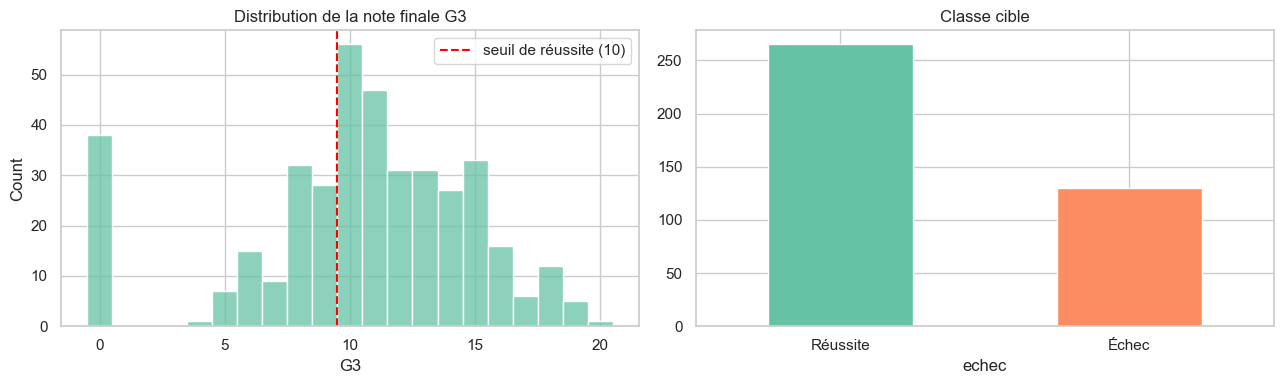

echec
0    0.671
1    0.329
Name: proportion, dtype: float64


In [3]:
df["echec"] = (df["G3"] < 10).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["G3"], bins=21, discrete=True, ax=ax[0])
ax[0].axvline(9.5, color="red", ls="--", label="seuil de réussite (10)")
ax[0].set_title("Distribution de la note finale G3"); ax[0].legend()
df["echec"].map({0: "Réussite", 1: "Échec"}).value_counts().plot.bar(ax=ax[1], color=["#66c2a5", "#fc8d62"])
ax[1].set_title("Classe cible"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(df["echec"].value_counts(normalize=True).round(3))

**Observations**
- Environ 33 % des élèves sont en échec : les classes sont déséquilibrées, sans l'être fortement. Une règle qui prédirait « réussite » pour tout le monde n'aurait qu'un taux d'erreur de 33 %, sans repérer un seul élève en difficulté. C'est pourquoi nous raisonnons en rappel et en précision plutôt qu'en taux d'erreur.
- La distribution présente un pic anormal à G3 = 0, une note très rare dans des conditions normales.


In [4]:
zeros = df[df["G3"] == 0]
print(f"{len(zeros)} élèves ont G3 = 0")
print("Parmi eux, absences moyennes :", zeros["absences"].mean().round(2), "vs", df[df.G3 > 0]["absences"].mean().round(2), "pour les autres")
print("G2 moyen de ces élèves :", zeros["G2"].mean().round(2))

38 élèves ont G3 = 0
Parmi eux, absences moyennes : 0.0 vs 6.32 pour les autres
G2 moyen de ces élèves : 4.66


Ces 38 élèves ont tous 0 absence, alors que la plupart ont eu des notes non nulles en G1 ou G2. Ce profil ne correspond pas à un élève qui aurait simplement tout raté : il s'agit très probablement d'élèves qui ont abandonné ou ne se sont pas présentés à l'examen final, et dont les absences n'ont plus été comptabilisées. C'est typiquement une question à poser à l'établissement (voir la conclusion). Nous les conservons dans la classe « échec » : du point de vue du lycée, un abandon est un échec qu'il aurait voulu prévenir.


### 2.3 Relations entre les variables et la cible

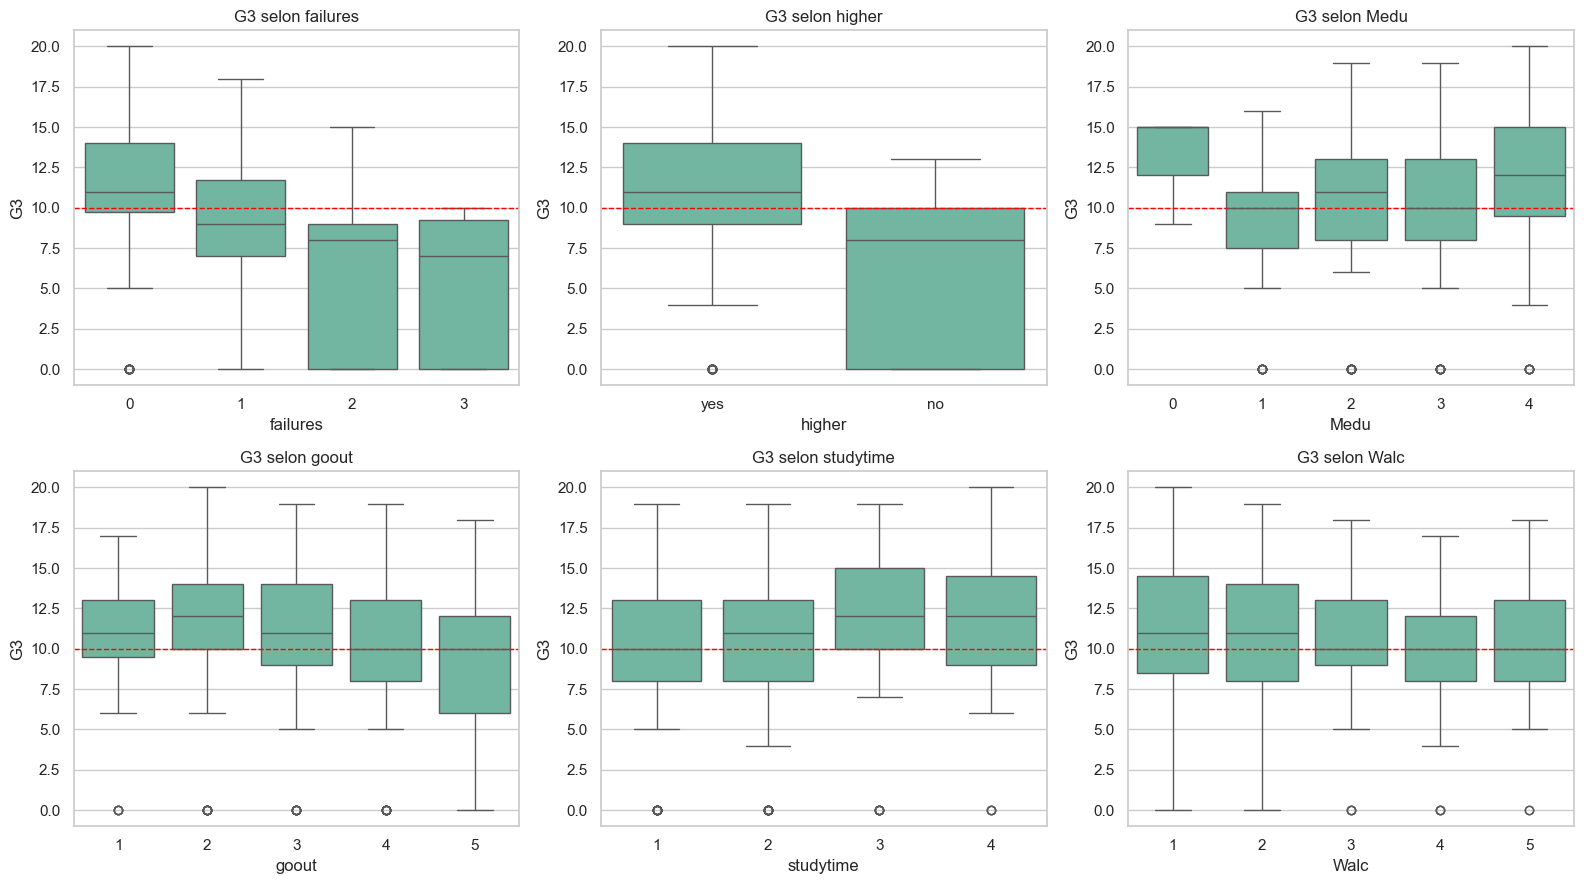

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ["failures", "higher", "Medu", "goout", "studytime", "Walc"]):
    sns.boxplot(data=df, x=col, y="G3", ax=ax)
    ax.axhline(10, color="red", ls="--", lw=1)
    ax.set_title(f"G3 selon {col}")
plt.tight_layout(); plt.show()

**Lecture des box plots au regard des hypothèses**
- **H1** : la note médiane passe de 11 sans échec passé à 9 dès un échec, puis 8 et 7. L'effet est net dès le premier échec.
- **H5** : les élèves qui ne visent pas d'études supérieures ont une médiane de 8, contre 11 pour les autres, mais ils ne sont que 20.
- **H3**, partiellement : les élèves dont la mère est diplômée du supérieur (`Medu = 4`) ont la meilleure médiane (12), mais la relation n'est pas régulière d'un niveau à l'autre et la dispersion reste forte.
- **H4**, nuancée : les élèves qui sortent beaucoup (`goout` = 4 ou 5) ont une médiane de 10, contre 11 à 12 pour les autres ; l'effet de l'alcool du week-end (`Walc`) est faible.
- Le temps d'étude (`studytime`) a un effet positif mais modeste.


### 2.4 Corrélations

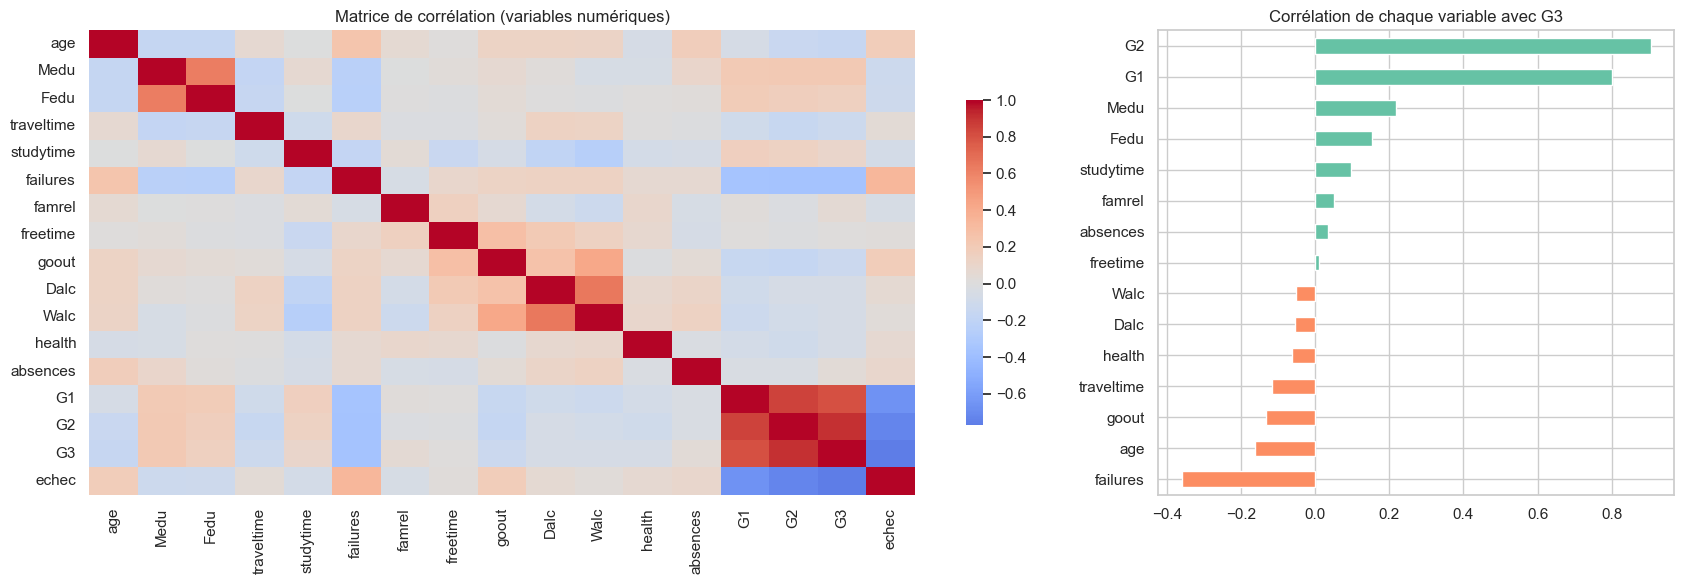

In [6]:
num = df.select_dtypes("number")
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(num.corr(), cmap="coolwarm", center=0, ax=ax[0], cbar_kws={"shrink": .7})
ax[0].set_title("Matrice de corrélation (variables numériques)")
c = num.corr()["G3"].drop(["G3", "echec"]).sort_values()
c.plot.barh(ax=ax[1], color=np.where(c > 0, "#66c2a5", "#fc8d62"))
ax[1].set_title("Corrélation de chaque variable avec G3")
plt.tight_layout(); plt.show()

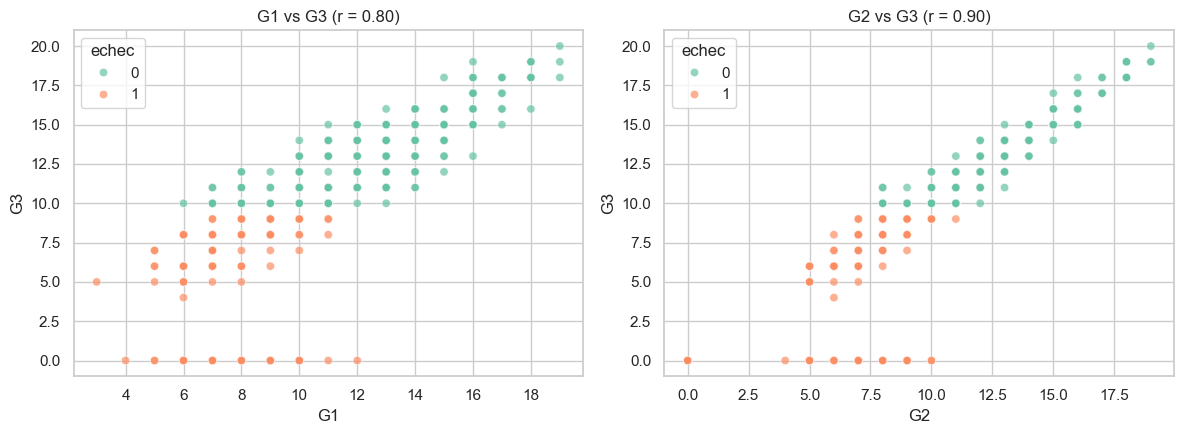

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, g in zip(ax, ["G1", "G2"]):
    sns.scatterplot(data=df, x=g, y="G3", hue="echec", palette={0: "#66c2a5", 1: "#fc8d62"}, alpha=.7, ax=a)
    a.set_title(f"{g} vs G3 (r = {df[g].corr(df.G3):.2f})")
plt.tight_layout(); plt.show()

**Lecture**
- **H2** : G1 (r ≈ 0,80) et G2 (r ≈ 0,90) sont très fortement corrélées à G3. Dans le scénario C, un modèle apprendra essentiellement « si G2 < 10, alors échec » : très performant, mais peu utile à l'établissement, qui dispose déjà de cette information dans le bulletin.
- En dehors des notes, toutes les corrélations sont faibles (|r| < 0,4). La plus forte est celle de `failures` (r ≈ -0,36), ce qui va dans le sens de H1. Il faut donc s'attendre à des performances modestes dans le scénario A.
- La corrélation de Pearson ne mesure que les relations linéaires : des modèles non linéaires comme les arbres peuvent exploiter des effets de seuil ou des interactions invisibles ici. Et une corrélation, même forte, ne dit rien de la causalité.
- `Dalc` et `Walc` sont corrélées entre elles, tout comme `Medu` et `Fedu` : nous traitons cette redondance en feature engineering.


## 3. Feature engineering

Le feature engineering consiste à transformer les variables brutes en features plus exploitables par les algorithmes. Nos choix :

| Transformation | Justification |
|---|---|
| Variables `yes/no` → 0/1 | Les modèles ne manipulent que des nombres |
| Variables nominales (`Mjob`, `Fjob`, `reason`, `guardian`) → un entier par modalité (`LabelEncoder`) | Même raison. Limite : ce codage introduit un ordre artificiel entre « teacher » et « health ». Les arbres y sont peu sensibles ; pour le SVM, c'est une approximation que nous acceptons sur des variables qui pèsent peu (section 6.2) |
| Échelles ordinales (1 à 5) conservées telles quelles | L'ordre a un sens (« très bas » < « très haut ») |
| `parents_edu = max(Medu, Fedu)` | Résume le niveau d'études du foyer et supprime une redondance |
| `alcool = (5·Dalc + 2·Walc) / 7` | Consommation moyenne sur la semaine (5 jours ouvrés, 2 jours de week-end), qui fusionne deux variables corrélées |
| `failures` conservée seule | Les box plots montrent un effet de seuil dès le premier échec (section 2.3). Nous avions d'abord ajouté une variable binaire `a_deja_echoue = failures > 0` pour aider le SVM à capter ce saut. Elle s'est révélée redondante : la retirer ne change pas les performances, et la Random Forest répartissait l'importance entre les deux variables, ce qui faisait croire à deux facteurs distincts (section 6.2). Nous l'avons donc supprimée |
| `absences` exclue des modèles | Les absences sont comptées sur toute l'année : elles ne sont connues ni à la rentrée, ni après le 1er trimestre. Les utiliser serait une **fuite de données** (*data leakage*). Nous la conservons à part (`log_absences`) pour le vérifier en section 7.2 |
| Mise à l'échelle entre 0 et 1 (`MinMaxScaler`) | Le SVM repose sur des distances : sans mise à l'échelle, l'âge (15 à 22) pèserait davantage qu'une variable binaire. Sans effet sur les arbres. Nous l'appliquons avant la séparation train / test, ce qui est sans conséquence ici puisque les bornes de presque toutes les variables sont fixées par construction (échelles de 1 à 5, notes sur 20, oui/non) |


In [8]:
X_brut = df.copy()
for c in ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]:
    X_brut[c] = (X_brut[c] == "yes").astype(int)
X_brut["school"]  = (X_brut["school"] == "GP").astype(int)
X_brut["sex"]     = (X_brut["sex"] == "F").astype(int)
X_brut["address"] = (X_brut["address"] == "U").astype(int)
X_brut["famsize"] = (X_brut["famsize"] == "GT3").astype(int)
X_brut["Pstatus"] = (X_brut["Pstatus"] == "T").astype(int)

X_brut["parents_edu"]   = X_brut[["Medu", "Fedu"]].max(axis=1)
X_brut["alcool"]        = (5 * X_brut["Dalc"] + 2 * X_brut["Walc"]) / 7
X_brut["log_absences"]  = np.log1p(X_brut["absences"])
X_brut = X_brut.drop(columns=["Medu", "Fedu", "Dalc", "Walc", "absences"])

# variables nominales : chaque modalité reçoit un numéro (LabelEncoder)
for c in ["Mjob", "Fjob", "reason", "guardian"]:
    X_brut[c] = LabelEncoder().fit_transform(X_brut[c])

y = X_brut.pop("echec")
X_brut = X_brut.drop(columns=["G3"])  # G3 définit la cible : la garder serait une fuite de données

# mise à l'échelle entre 0 et 1 (MinMaxScaler) : utile pour le SVM, sans effet sur les arbres
X_all = pd.DataFrame(MinMaxScaler().fit_transform(X_brut), columns=X_brut.columns, index=X_brut.index)

profil = [c for c in X_all.columns if c not in ("G1", "G2", "log_absences")]
SCENARIOS = {"A (rentrée)": profil, "B (+G1)": profil + ["G1"], "C (+G1+G2)": profil + ["G1", "G2"]}
print(f"{len(profil)} features de profil après feature engineering")


27 features de profil après feature engineering


**Découpage train / test.** Nous mettons de côté 20 % des élèves comme jeu de test, qui ne sert qu'à l'évaluation finale. Sur les 316 élèves d'entraînement, les modèles sont comparés et réglés par validation croisée à 5 plis. Pour mesurer la stabilité des résultats, nous répétons aussi 20 découpages aléatoires apprentissage / validation et regardons la moyenne et la dispersion des scores : avec si peu d'élèves, un découpage unique dépendrait trop du hasard.


In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y, test_size=0.2, random_state=SEED)
CV = 5  # validation croisée à 5 plis
print("Train :", X_tr.shape, "| Test :", X_te.shape, "| taux d'échec train/test :", y_tr.mean().round(3), y_te.mean().round(3))

def nouveau(m):
    """Copie vierge d'un modèle, avec les mêmes hyperparamètres."""
    return m.__class__(**m.get_params())

def tirages(m, X, yy, n=20):
    """n découpages aléatoires apprentissage / validation (75 % / 25 %),
    on renvoie le rappel et la précision obtenus sur la partie validation à chaque tirage."""
    out = []
    for i in range(n):
        Xa, Xv, ya, yv = train_test_split(X, yy, test_size=0.25, random_state=i)
        p = nouveau(m).fit(Xa, ya).predict(Xv)
        out.append((recall_score(yv, p), precision_score(yv, p, zero_division=0)))
    return np.array(out)


Train : (316, 30) | Test : (79, 30) | taux d'échec train/test : 0.326 0.342


### 3.1 Analyse non supervisée : existe-t-il des profils types d'élèves ?

Avant l'apprentissage supervisé, nous cherchons si les élèves se regroupent naturellement, sans utiliser la cible : c'est de l'apprentissage non supervisé. Nous combinons :
- une ACP, pour projeter les 27 features de profil sur deux axes et les visualiser ;
- un K-means, pour former des groupes d'élèves similaires.

Si l'un des groupes présente un taux d'échec très différent des autres, le profil contient de l'information exploitable pour la prédiction.


  File "c:\Users\Utilisateur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Utilisateur\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Utilisateur\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Utilisateur\a

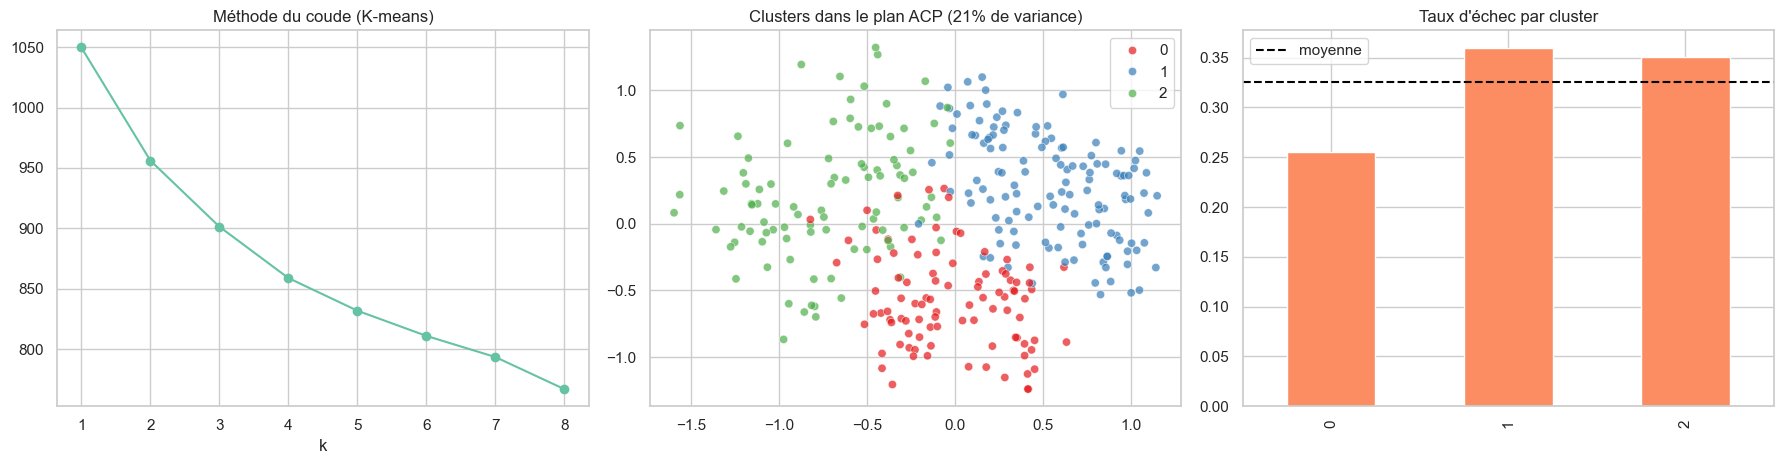

,age,failures,goout,alcool,studytime,parents_edu,higher,school
0,16.48,0.21,3.27,2.07,1.84,3.26,0.97,0.94
1,16.68,0.28,3.09,1.52,2.36,3.01,0.98,0.91
2,17.10,0.53,3.16,1.72,1.83,2.63,0.86,0.82


In [10]:
Z = X_tr[profil].values  # déjà mis à l'échelle entre 0 et 1
pca = PCA(n_components=2, random_state=SEED).fit(Z); P = pca.transform(Z)
inerties = [KMeans(k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in range(1, 9)]
km = KMeans(3, n_init=10, random_state=SEED).fit(Z)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot(range(1, 9), inerties, "o-"); ax[0].set_title("Méthode du coude (K-means)"); ax[0].set_xlabel("k")
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=km.labels_, palette="Set1", ax=ax[1], alpha=.7)
ax[1].set_title(f"Clusters dans le plan ACP ({pca.explained_variance_ratio_.sum():.0%} de variance)")
taux = pd.Series(y_tr.values).groupby(km.labels_).mean()
taux.plot.bar(ax=ax[2], color="#fc8d62"); ax[2].axhline(y_tr.mean(), color="k", ls="--", label="moyenne")
ax[2].set_title("Taux d'échec par cluster"); ax[2].legend()
plt.tight_layout(); plt.show()
X_brut.loc[X_tr.index, profil].groupby(km.labels_).mean()[["age", "failures", "goout", "alcool", "studytime", "parents_edu", "higher", "school"]].round(2)


**Interprétation**
- Les deux premières composantes de l'ACP n'expliquent qu'environ 21 % de la variance, et la courbe du coude ne présente pas de cassure nette : il n'existe pas de groupes naturellement bien séparés, les élèves forment plutôt un continuum. Le choix de k = 3 est donc une commodité d'analyse, pas une structure des données.
- Les trois clusters ont des taux d'échec assez proches (26 %, 35 % et 36 %). Le cluster n° 2 regroupe des élèves plus âgés, ayant plus souvent déjà échoué, dont les parents sont moins diplômés et qui visent moins souvent des études supérieures, ce qui va dans le sens de H1, H3 et H5 ; mais son taux d'échec n'est pas plus élevé que celui du cluster n° 1, qui se distingue surtout par un temps d'étude plus important et une consommation d'alcool plus faible. Les groupes formés sans la cible ne séparent donc pas clairement les élèves à risque.
- Le K-means accorde le même poids à toutes les variables : une variable redondante y compte double. Dans une première version, qui contenait aussi la variable binaire `a_deja_echoue`, un cluster à 51 % d'échec se détachait nettement, car les échecs passés pesaient deux fois dans le calcul des distances. Ce résultat dépendait donc d'un choix de codage, et non d'une structure réelle des données.

Le profil contient un signal, porté notamment par les échecs passés, mais faible et dilué parmi de nombreuses variables peu informatives. Il ne faut pas attendre de performances spectaculaires dans le scénario A.


## 4. Apprentissage

### Choix des algorithmes
Nous comparons des modèles de complexité croissante. Comme référence, nous ajoutons la règle « tout le monde réussit » : tout modèle doit faire mieux.

| Modèle | Pourquoi |
|---|---|
| Naive Bayes | Modèle probabiliste simple, fondé sur le théorème de Bayes et l'hypothèse (naïve) d'indépendance des variables. Référence rapide |
| SVM | Cherche la frontière qui sépare les classes avec la plus grande marge. Le paramètre `C` règle le compromis entre marge et erreurs d'entraînement (régularisation), le noyau permet des frontières non linéaires. Robuste au déséquilibre des classes |
| Arbre de décision | Règles lisibles par un enseignant, capte les effets de seuil, mais très sujet au surapprentissage |
| Random Forest | Bagging d'arbres avec tirage aléatoire des variables : réduit la variance d'un arbre seul |
| Gradient Boosting | Arbres peu profonds construits séquentiellement, chacun corrigeant les erreurs des précédents : réduit le biais |

Le SVM nécessite des variables à la même échelle, d'où la mise à l'échelle entre 0 et 1 de la section 3. L'option `class_weight="balanced"` donne plus de poids aux élèves en échec, minoritaires, pendant l'apprentissage, ce qui va dans le sens de notre objectif de rappel.


In [11]:
MODELES = {
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(class_weight="balanced", random_state=SEED),
    "Arbre de décision": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

lignes = []
for scen, cols in SCENARIOS.items():
    # référence : prédire « réussite » pour tout le monde
    lignes.append({"Scénario": scen, "Modèle": "Toujours « réussite »", "rappel": 0.0, "précision": 0.0,
                   "taux d'erreur": y_tr.mean(), "rappel train": 0.0})
    for nom, m in MODELES.items():
        rap = cross_val_score(m, X_tr[cols], y_tr, cv=CV, scoring="recall").mean()
        pre = cross_val_score(m, X_tr[cols], y_tr, cv=CV, scoring="precision").mean()
        acc = cross_val_score(m, X_tr[cols], y_tr, cv=CV).mean()
        rap_train = recall_score(y_tr, nouveau(m).fit(X_tr[cols], y_tr).predict(X_tr[cols]))
        lignes.append({"Scénario": scen, "Modèle": nom, "rappel": rap, "précision": pre,
                       "taux d'erreur": 1 - acc, "rappel train": rap_train})
res = pd.DataFrame(lignes)
res.round(3)


,Scénario,Modèle,rappel,précision,taux d'erreur,rappel train
0,A (rentrée),Toujours « réussite »,0.000,0.000,0.326,0.000
1,A (rentrée),Naive Bayes,0.350,0.586,0.297,0.417
2,A (rentrée),SVM,0.476,0.445,0.364,0.835
3,A (rentrée),Arbre de décision,0.351,0.360,0.411,1.000
4,A (rentrée),Random Forest,0.213,0.605,0.304,1.000
5,A (rentrée),Gradient Boosting,0.330,0.441,0.354,0.864
6,B (+G1),Toujours « réussite »,0.000,0.000,0.326,0.000
7,B (+G1),Naive Bayes,0.524,0.720,0.225,0.612
8,B (+G1),SVM,0.727,0.614,0.237,0.961
9,B (+G1),Arbre de décision,0.584,0.586,0.263,1.000


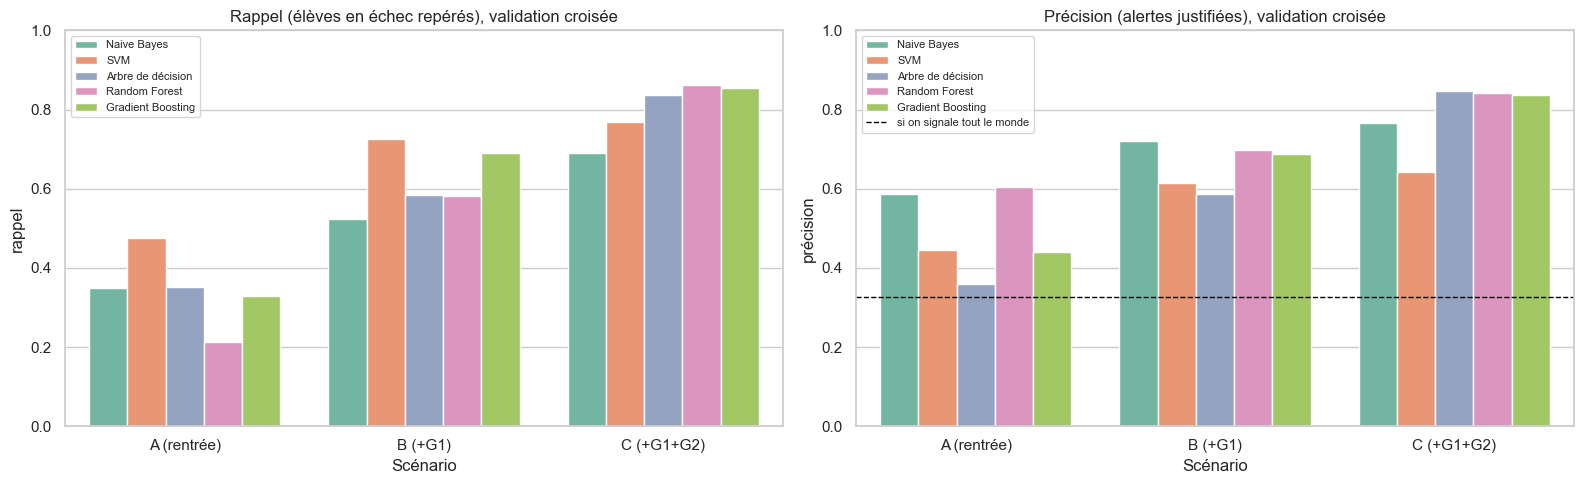

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
r = res[res.Modèle != "Toujours « réussite »"]
sns.barplot(data=r, x="Scénario", y="rappel", hue="Modèle", ax=ax[0])
ax[0].set_title("Rappel (élèves en échec repérés), validation croisée"); ax[0].set_ylim(0, 1); ax[0].legend(fontsize=8)
sns.barplot(data=r, x="Scénario", y="précision", hue="Modèle", ax=ax[1])
ax[1].axhline(y_tr.mean(), color="k", ls="--", lw=1, label="si on signale tout le monde")
ax[1].set_title("Précision (alertes justifiées), validation croisée"); ax[1].set_ylim(0, 1); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**Lecture des résultats**
- La règle « tout le monde réussit » a un rappel nul alors que son taux d'erreur n'est que de 33 % : le taux d'erreur seul serait trompeur.
- Le moment de la prédiction change tout (H2) : les performances progressent nettement du scénario A au scénario B, puis au C. Une seule note de premier trimestre apporte plus que les 27 variables de profil réunies.
- Scénario A : le meilleur rappel est celui du SVM (0,48), pour une précision de 0,45. Tous les modèles restent modestes, comme l'annonçait l'exploration : environ un élève signalé sur deux échoue réellement.
- Naive Bayes signale peu d'élèves : sa précision est la meilleure à la rentrée (0,59) mais son rappel faible (0,35), et il progresse peu quand G1 devient disponible.
- Surapprentissage : la colonne `rappel train` est calculée sur les élèves d'entraînement eux-mêmes. L'arbre de décision et la Random Forest y atteignent 1, contre environ 0,40 en validation à la rentrée : avec leurs réglages par défaut, ils apprennent par cœur les élèves d'entraînement. Le réglage des hyperparamètres doit corriger ce point.

Nous écartons désormais le scénario C, qui arrive trop tard pour agir, et suivons en parallèle les scénarios A et B.


## 5. Réglage des hyperparamètres

Un hyperparamètre est un réglage du modèle fixé avant l'apprentissage, contrairement aux paramètres appris sur les données (seuils des arbres, vecteurs supports du SVM). Il contrôle la complexité du modèle, donc le compromis entre sous-apprentissage (biais élevé) et surapprentissage (variance élevée).

### 5.1 Surapprentissage et profondeur d'un arbre


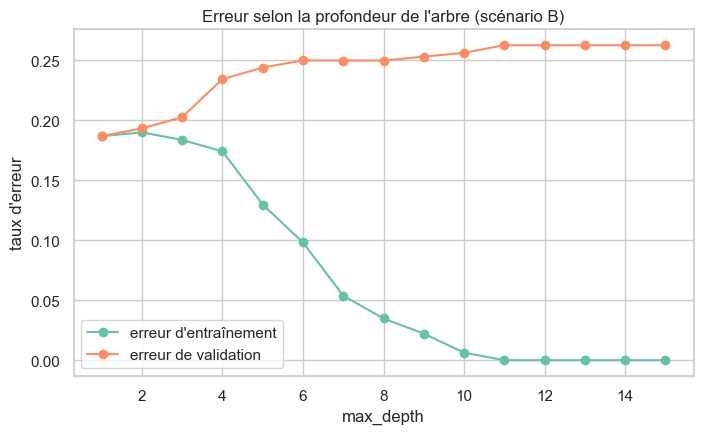

In [13]:
cols_B = SCENARIOS["B (+G1)"]
prof = np.arange(1, 16)
err_train, err_val = [], []
for d in prof:
    arbre_d = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=SEED)
    err_train.append(1 - arbre_d.fit(X_tr[cols_B], y_tr).score(X_tr[cols_B], y_tr))
    err_val.append(1 - cross_val_score(arbre_d, X_tr[cols_B], y_tr, cv=CV).mean())
plt.figure(figsize=(8, 4.5))
plt.plot(prof, err_train, "o-", label="erreur d'entraînement"); plt.plot(prof, err_val, "o-", label="erreur de validation")
plt.xlabel("max_depth"); plt.ylabel("taux d'erreur"); plt.title("Erreur selon la profondeur de l'arbre (scénario B)")
plt.legend(); plt.show()


La courbe illustre le compromis biais-variance. L'erreur d'entraînement décroît avec la profondeur et devient nulle à partir de 11 niveaux : l'arbre finit par apprendre par cœur les élèves d'entraînement. L'erreur de validation est au contraire minimale pour une profondeur de 1 à 3 (19 à 20 %), puis dépasse 23 % dès la profondeur 4 et atteint 26 % pour les arbres les plus profonds : au-delà, l'arbre ajuste le bruit des données, c'est le surapprentissage. Le sous-apprentissage n'apparaît pas ici, car une seule coupure sur G1 suffit déjà à bien séparer les élèves, ce que nous retrouvons en section 7.6. Le bon réglage est donc un arbre peu profond, qui a en plus l'avantage d'être lisible.

### 5.2 Hyperparamètres importants et recherche par grille

| Modèle | Hyperparamètre | Rôle |
|---|---|---|
| SVM | `C` | Compromis marge / erreurs : un petit C élargit la marge et contraint le modèle (régularisation forte), un grand C colle aux données d'entraînement |
| | `kernel` | Forme de la frontière : linéaire, ou non linéaire avec le noyau gaussien `rbf` (astuce du noyau) |
| Random Forest | `n_estimators` | Nombre d'arbres : plus il est grand, plus la forêt est stable, sans risque de surapprentissage, au prix du temps de calcul |
| | `max_depth` | Profondeur maximale de chaque arbre, principal levier contre le surapprentissage |
| | `min_samples_leaf` | Nombre minimal d'élèves par feuille : évite des règles fondées sur un ou deux élèves |
| | `max_features` | Nombre de variables tirées à chaque nœud : diversifie les arbres |
| Gradient Boosting | `learning_rate` et `n_estimators` | Pas d'apprentissage et nombre d'arbres, à régler ensemble : un petit pas demande plus d'arbres (shrinkage) |
| | `max_depth` | Généralement faible (2 à 4) : chaque arbre reste un apprenant faible |
| | `subsample` | Fraction des élèves utilisée par arbre : introduit de l'aléa et régularise |

Nous utilisons `GridSearchCV` : chaque combinaison est évaluée par validation croisée à 5 plis, en mesurant rappel et précision, puis nous appliquons la règle de choix de la section 1 (meilleur rappel parmi les combinaisons de précision au moins égale à 0,40). Le jeu de test n'intervient pas à cette étape.


In [14]:
PRECISION_MIN = 0.40

def choix(cv_results):
    """Règle de choix : parmi les réglages dont la précision moyenne atteint PRECISION_MIN,
    on garde celui qui a le meilleur rappel."""
    rap = np.array(cv_results["mean_test_rappel"]); pre = np.array(cv_results["mean_test_precision"])
    rap = np.where(pre >= PRECISION_MIN, rap, -1)
    return int(np.argmax(rap))

grilles = {
    "SVM": (SVC(class_weight="balanced", random_state=SEED),
            {"kernel": ["linear", "rbf"], "C": [0.001, 0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                      {"n_estimators": [300], "max_depth": [3, 5, 8, None],
                       "min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED),
                          {"learning_rate": [0.03, 0.1], "n_estimators": [100, 300],
                           "max_depth": [2, 3], "subsample": [0.8, 1.0]}),
}
meilleurs, recap = {}, []
for scen in ["A (rentrée)", "B (+G1)"]:
    for nom, (m, g) in grilles.items():
        gs = GridSearchCV(m, g, cv=CV, scoring={"rappel": "recall", "precision": "precision"}, refit=choix, n_jobs=-1)
        gs.fit(X_tr[SCENARIOS[scen]], y_tr)
        avant = res.query("Scénario == @scen and Modèle == @nom").iloc[0]
        recap.append({"Scénario": scen, "Modèle": nom,
                      "rappel défaut": avant["rappel"], "précision défaut": avant["précision"],
                      "rappel réglé": gs.cv_results_["mean_test_rappel"][gs.best_index_],
                      "précision réglée": gs.cv_results_["mean_test_precision"][gs.best_index_],
                      "Meilleurs hyperparamètres": gs.best_params_})
        meilleurs[(scen, nom)] = gs.best_estimator_
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(recap).round(3)


,Scénario,Modèle,rappel défaut,précision défaut,rappel réglé,précision réglée,Meilleurs hyperparamètres
0,A (rentrée),SVM,0.476,0.445,0.592,0.463,"{'C': 10, 'kernel': 'linear'}"
1,A (rentrée),Random Forest,0.213,0.605,0.456,0.471,"{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}"
2,A (rentrée),Gradient Boosting,0.330,0.441,0.369,0.407,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 1.0}"
3,B (+G1),SVM,0.727,0.614,0.826,0.677,"{'C': 10, 'kernel': 'linear'}"
4,B (+G1),Random Forest,0.582,0.697,0.961,0.645,"{'max_depth': 3, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}"
5,B (+G1),Gradient Boosting,0.690,0.688,0.748,0.712,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'subsample': 0.8}"


**Discussion**
- Le réglage fait nettement progresser le rappel sans dégrader beaucoup la précision, ce que demande notre règle de choix. Après le 1er trimestre, la Random Forest passe de 0,80 à 0,96 de rappel avec des arbres de profondeur 3 seulement, ce qui confirme que la profondeur est le principal levier contre le surapprentissage.
- Le SVM retient un noyau linéaire dans les deux scénarios : une frontière simple suffit, un noyau plus flexible n'apporte rien sur ces données.
- Avec environ 63 élèves par pli, les scores varient de plusieurs points d'un pli à l'autre : de petits écarts entre modèles ne doivent pas être surinterprétés.


### 5.3 Les écarts entre modèles sont-ils significatifs ?

Avec 316 élèves d'entraînement, le score obtenu dépend fortement du découpage. Pour ne pas retenir un modèle par chance, nous tirons 20 découpages aléatoires apprentissage / validation (75 % / 25 %), entraînons chaque modèle réglé sur chacun d'eux, et comparons la moyenne et la dispersion du rappel et de la précision. La règle de choix est appliquée à ces moyennes.


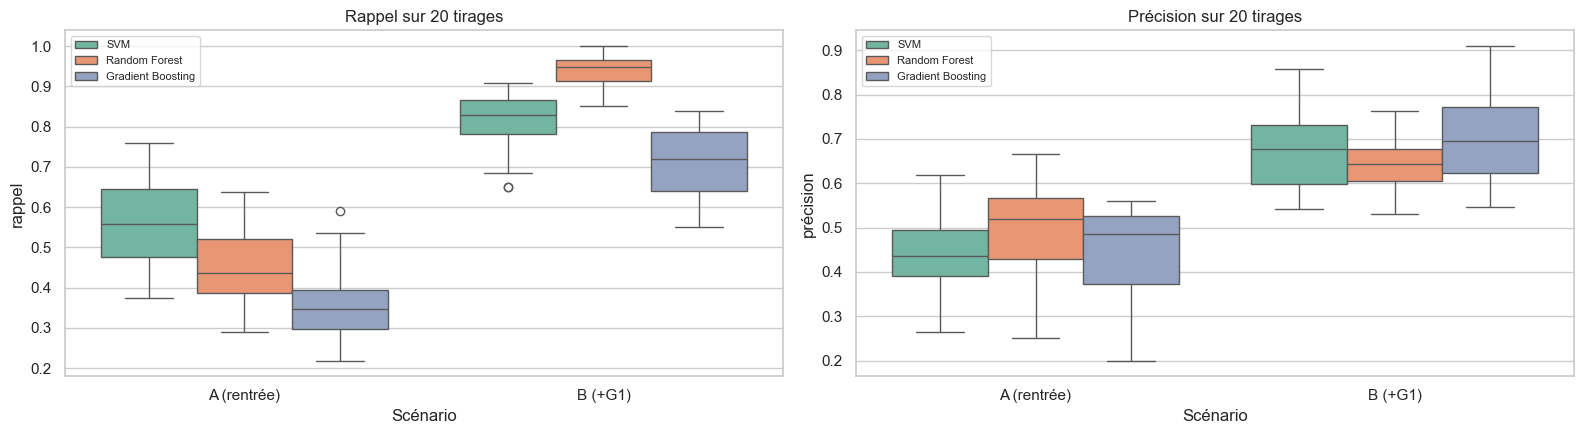

rappel        précision       
                                mean    std      mean    std
Scénario    Modèle                                          
A (rentrée) Gradient Boosting  0.354  0.100     0.441  0.104
            Random Forest      0.447  0.101     0.493  0.111
            SVM                0.563  0.115     0.441  0.091
B (+G1)     Gradient Boosting  0.709  0.091     0.708  0.105
            Random Forest      0.939  0.039     0.650  0.066
            SVM                0.814  0.077     0.673  0.086

In [15]:
rob = []
for (scen, nom), m in meilleurs.items():
    for rap, pre in tirages(m, X_tr[SCENARIOS[scen]], y_tr):
        rob.append({"Scénario": scen, "Modèle": nom, "rappel": rap, "précision": pre})
rob = pd.DataFrame(rob)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.boxplot(data=rob, x="Scénario", y="rappel", hue="Modèle", ax=ax[0]); ax[0].set_title("Rappel sur 20 tirages")
sns.boxplot(data=rob, x="Scénario", y="précision", hue="Modèle", ax=ax[1]); ax[1].set_title("Précision sur 20 tirages")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
rob.groupby(["Scénario", "Modèle"])[["rappel", "précision"]].agg(["mean", "std"]).round(3)


In [16]:
# règle de choix : meilleur rappel moyen parmi les modèles dont la précision moyenne atteint PRECISION_MIN
moy = rob.groupby(["Scénario", "Modèle"])[["rappel", "précision"]].mean().reset_index()
CHOIX = {}
for scen in ["A (rentrée)", "B (+G1)"]:
    cand = moy[(moy.Scénario == scen) & (moy.précision >= PRECISION_MIN)]
    CHOIX[scen] = cand.sort_values("rappel").iloc[-1]["Modèle"]
print("Modèles retenus :", CHOIX)


Modèles retenus : {'A (rentrée)': 'SVM', 'B (+G1)': 'Random Forest'}


**Lecture.** La dispersion d'un tirage à l'autre est forte (écart-type de 0,03 à 0,12) : un écart de quelques points entre deux modèles n'est pas significatif.
- Scénario A : les trois modèles dépassent la précision minimale de 0,40. Le SVM a le meilleur rappel (0,56, contre 0,50 pour la Random Forest et 0,35 pour le Gradient Boosting), pour une précision comparable (0,44 contre 0,47 pour la Random Forest). Son avantage sur la Random Forest reste toutefois inférieur à la dispersion entre tirages. Nous le retenons.
- Scénario B : la Random Forest repère en moyenne 95 % des élèves en échec, avec une précision de 0,65, et c'est le modèle le plus stable (écart-type du rappel de 0,03). Nous la retenons.


## 6. Évaluation finale sur le jeu de test

Pour chaque scénario, le modèle retenu en section 5.3 est évalué une seule fois sur les 79 élèves du jeu de test.


=== Scénario A (rentrée) : SVM ===
rappel = 0.556 | précision = 0.536 | taux d'erreur = 0.316
=== Scénario B (+G1) : Random Forest ===
rappel = 0.963 | précision = 0.667 | taux d'erreur = 0.177


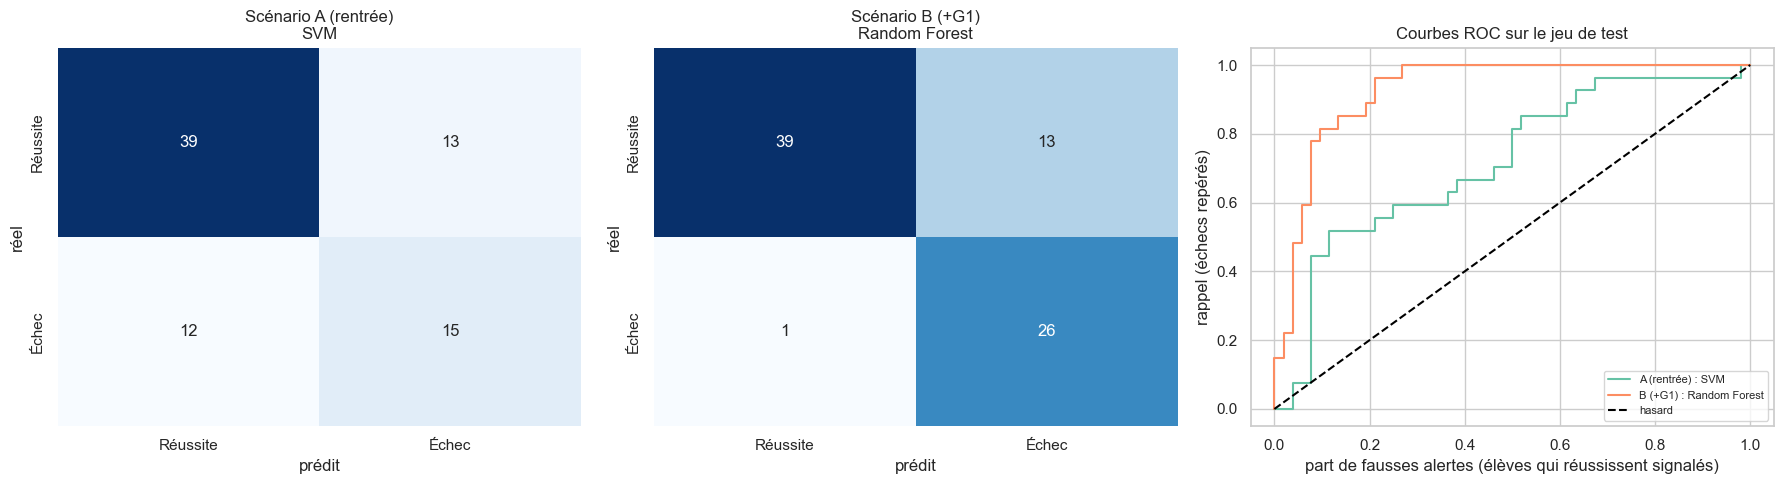

In [17]:
def score_continu(m, X):
    """Score d'échec du modèle : probabilité pour les modèles qui en donnent une, distance à la frontière pour le SVM."""
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)

def courbe_roc(yy, s):
    """Courbe ROC construite à la main : on fait varier le seuil de décision et on calcule,
    pour chaque seuil, la part d'échecs repérés et la part de fausses alertes parmi les élèves qui réussissent."""
    seuils = np.r_[np.inf, np.sort(np.unique(s))[::-1]]
    vp = [((s >= t) & (yy == 1)).sum() / (yy == 1).sum() for t in seuils]
    fp = [((s >= t) & (yy == 0)).sum() / (yy == 0).sum() for t in seuils]
    return np.array(fp), np.array(vp)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, (scen, nom) in enumerate(CHOIX.items()):
    m = meilleurs[(scen, nom)]; cols = SCENARIOS[scen]
    pred = m.predict(X_te[cols]); mc = confusion_matrix(y_te, pred)
    print(f"=== Scénario {scen} : {nom} ===")
    print(f"rappel = {recall_score(y_te, pred):.3f} | précision = {precision_score(y_te, pred):.3f} | "
          f"taux d'erreur = {1 - accuracy_score(y_te, pred):.3f}")
    sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[i],
                xticklabels=["Réussite", "Échec"], yticklabels=["Réussite", "Échec"])
    ax[i].set_xlabel("prédit"); ax[i].set_ylabel("réel"); ax[i].set_title(f"Scénario {scen}\n{nom}")
    fpr, tpr = courbe_roc(y_te.values, score_continu(m, X_te[cols]))
    ax[2].plot(fpr, tpr, label=f"{scen} : {nom}")
ax[2].plot([0, 1], [0, 1], "k--", label="hasard")
ax[2].set_xlabel("part de fausses alertes (élèves qui réussissent signalés)"); ax[2].set_ylabel("rappel (échecs repérés)")
ax[2].set_title("Courbes ROC sur le jeu de test"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


**Lecture des matrices de confusion.** La ligne du bas correspond aux élèves réellement en échec : la case de droite compte ceux que le modèle a repérés (vrais positifs), celle de gauche ceux qu'il a manqués (faux négatifs). La case en haut à droite compte les élèves signalés alors qu'ils ont réussi (faux positifs). On en déduit :
- rappel = vrais positifs / (vrais positifs + faux négatifs) ;
- précision = vrais positifs / (vrais positifs + faux positifs).

La courbe ROC s'obtient en faisant varier le seuil de décision du modèle : pour chaque seuil, on place la part de fausses alertes parmi les élèves qui réussissent (abscisse) et le rappel (ordonnée). Plus la courbe s'approche du coin supérieur gauche, meilleur est le modèle ; la diagonale correspond au hasard.


**Traduction pour l'établissement**
- Scénario B (Random Forest réglée) : après le premier trimestre, le modèle repère 26 des 27 élèves qui vont échouer (rappel 0,96), en signalant 13 élèves qui auraient réussi (précision 0,67). Pour un lycée, le compromis est très acceptable : 39 élèves à suivre, parmi lesquels presque tous ceux qui en ont besoin, avec deux trimestres pour agir.
- Scénario A (SVM linéaire) : à la rentrée, le modèle repère environ un élève en échec sur deux (15 sur 27), avec 13 fausses alertes (précision 0,54). Il peut servir de premier filtre, par exemple pour proposer un entretien individuel, mais pas de verdict.
- Les courbes ROC confirment l'écart entre les deux scénarios : celle du scénario B longe le coin supérieur gauche, celle du scénario A s'écarte bien moins de la diagonale.

### 6.1 Ajuster le seuil de décision aux moyens de l'établissement
Par défaut, un élève est signalé si sa probabilité d'échec estimée dépasse 0,5. Le lycée peut déplacer ce seuil selon ses moyens : l'abaisser augmente le rappel (moins d'élèves oubliés) au prix de davantage de fausses alertes.


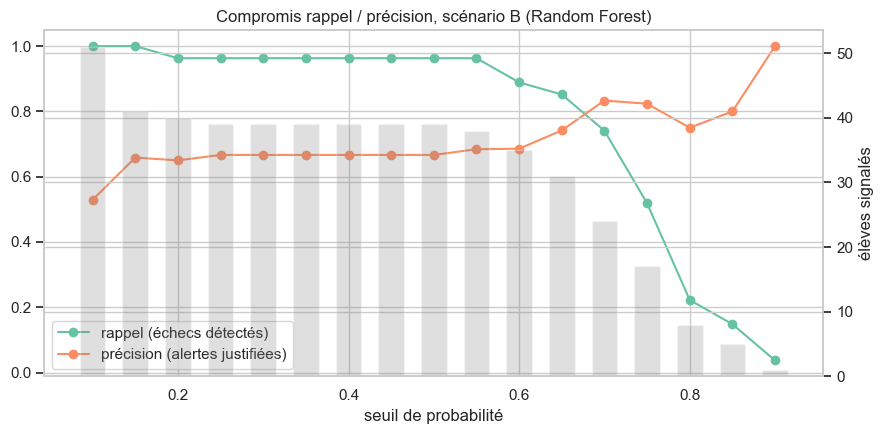

,seuil,rappel,précision,élèves signalés
0,0.10,1.00,0.53,51
1,0.15,1.00,0.66,41
2,0.20,0.96,0.65,40
3,0.25,0.96,0.67,39
4,0.30,0.96,0.67,39
5,0.35,0.96,0.67,39
6,0.40,0.96,0.67,39
7,0.45,0.96,0.67,39
8,0.50,0.96,0.67,39
9,0.55,0.96,0.68,38


In [18]:
nom, m = CHOIX["B (+G1)"], meilleurs[("B (+G1)", CHOIX["B (+G1)"])]; cols = SCENARIOS["B (+G1)"]
if not hasattr(m, "predict_proba"):  # le SVM ne donne pas de probabilité : on prend alors la Random Forest
    nom, m = "Random Forest", meilleurs[("B (+G1)", "Random Forest")]
proba = m.predict_proba(X_te[cols])[:, 1]
seuils = np.arange(0.1, 0.91, 0.05)
t = pd.DataFrame({"seuil": seuils,
                  "rappel": [recall_score(y_te, proba >= s) for s in seuils],
                  "précision": [precision_score(y_te, proba >= s, zero_division=0) for s in seuils],
                  "élèves signalés": [(proba >= s).sum() for s in seuils]})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t.seuil, t.rappel, "o-", label="rappel (échecs détectés)")
ax.plot(t.seuil, t.précision, "o-", label="précision (alertes justifiées)")
ax2 = ax.twinx(); ax2.bar(t.seuil, t["élèves signalés"], width=.03, alpha=.25, color="grey"); ax2.set_ylabel("élèves signalés")
ax.set_xlabel("seuil de probabilité"); ax.set_title(f"Compromis rappel / précision, scénario B ({nom})"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
t.round(2)


Sur le jeu de test, le rappel reste supérieur ou égal à 0,96 pour tout seuil compris entre 0,1 et 0,6 : le modèle sépare bien les élèves à risque. Au-delà, il chute rapidement. Un seuil de 0,7 offre un compromis intéressant : 27 élèves signalés, dont 8 sur 10 à juste titre, pour 81 % des élèves en difficulté repérés. Un lycée aux moyens très limités pourrait aller jusqu'à 0,75 : 17 élèves signalés, mais près de la moitié des élèves en difficulté passeraient alors inaperçus. Le choix du seuil n'est pas une question technique mais une décision de l'établissement, qui dépend du nombre d'élèves qu'il peut accompagner.

### 6.2 Quelles variables comptent ? (feature importance)


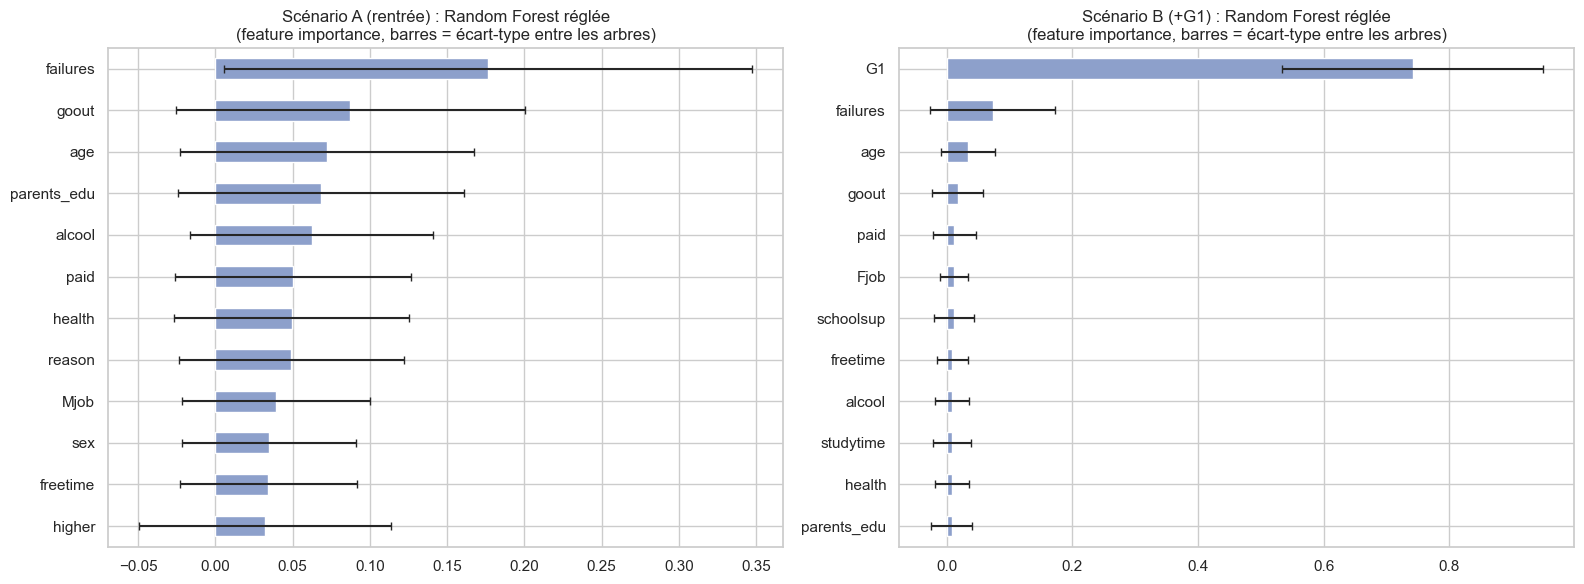

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, scen in zip(ax, ["A (rentrée)", "B (+G1)"]):
    rf = meilleurs[(scen, "Random Forest")]; cols = SCENARIOS[scen]
    imp = pd.Series(rf.feature_importances_, index=cols)
    std = pd.Series(np.std([t.feature_importances_ for t in rf.estimators_], axis=0), index=cols)
    top = imp.sort_values().tail(12)
    top.plot.barh(ax=a, xerr=std[top.index], color="#8da0cb", capsize=3)
    a.set_title(f"Scénario {scen} : Random Forest réglée\n(feature importance, barres = écart-type entre les arbres)")
plt.tight_layout(); plt.show()

La feature importance d'une Random Forest mesure la contribution moyenne de chaque variable, sur l'ensemble des arbres, à l'homogénéité des feuilles (réussite ou échec). Les barres d'erreur représentent la dispersion entre arbres. Nous l'utilisons sur la Random Forest réglée des deux scénarios, y compris à la rentrée où le modèle retenu est le SVM : les deux modèles ont des performances proches et la forêt donne une lecture directe des variables utilisées.

**Retour sur les hypothèses**
- **H1** confirmée : à la rentrée, les échecs passés (`failures`) sont nettement en tête.
- **H4** confirmée pour les sorties (`goout`), qui arrivent en deuxième position, devant l'âge. L'alcool, peu lié à la note dans les box plots, ressort aussi, un peu plus loin : son effet passe sans doute par des interactions avec d'autres variables, que la corrélation linéaire ne voit pas.
- **H3** partiellement : le niveau d'études des parents (`parents_edu`) arrive en quatrième position, avec une importance nettement plus faible que celle des échecs passés.
- **H5** : l'effet visible dans les box plots ne concerne que 20 élèves, d'où une importance faible.
- **H2** confirmée : après le 1er trimestre, G1 représente à elle seule près des trois quarts de l'importance totale. Le modèle se comporte presque comme une règle sur la note du premier trimestre, affinée par le profil.

Deux précautions de lecture. D'abord, cette mesure favorise les variables qui prennent beaucoup de valeurs (âge, alcool, métiers des parents codés de 0 à 4), car elles offrent plus de seuils de coupure. Ensuite, une variable importante n'est pas une cause : si `goout` aide à prédire l'échec, cela ne prouve pas que sortir fait échouer, les deux pouvant dépendre d'un troisième facteur (motivation, cadre familial).


## 7. Analyses complémentaires

Les sections précédentes répondent au problème posé. Cette partie éprouve la solidité des conclusions et explore d'autres aspects du cas d'usage.


In [20]:
def cv_score(m, X, yy, sc="recall"):
    r = cross_val_score(m, X, yy, cv=10, scoring=sc)
    return r.mean(), r.std()

def rmse(y_vrai, y_pred):
    return np.sqrt(mean_squared_error(y_vrai, y_pred))

modele_A = meilleurs[("A (rentrée)", CHOIX["A (rentrée)"])]
modele_B = meilleurs[("B (+G1)", CHOIX["B (+G1)"])]


### 7.1 Et si l'on prédisait la note exacte ? (régression)

Nous prédisons ici directement G3 sur 20. La métrique devient la RMSE (racine de l'erreur quadratique moyenne), exprimée en points ; comme elle élève les erreurs au carré, elle pénalise fortement les grosses erreurs.

La question est de savoir si le ML fait mieux qu'une règle naïve qu'un enseignant appliquerait sans calcul : prédire la moyenne de la classe à la rentrée, ou recopier la dernière note connue (G3 = G1, puis G3 = G2).


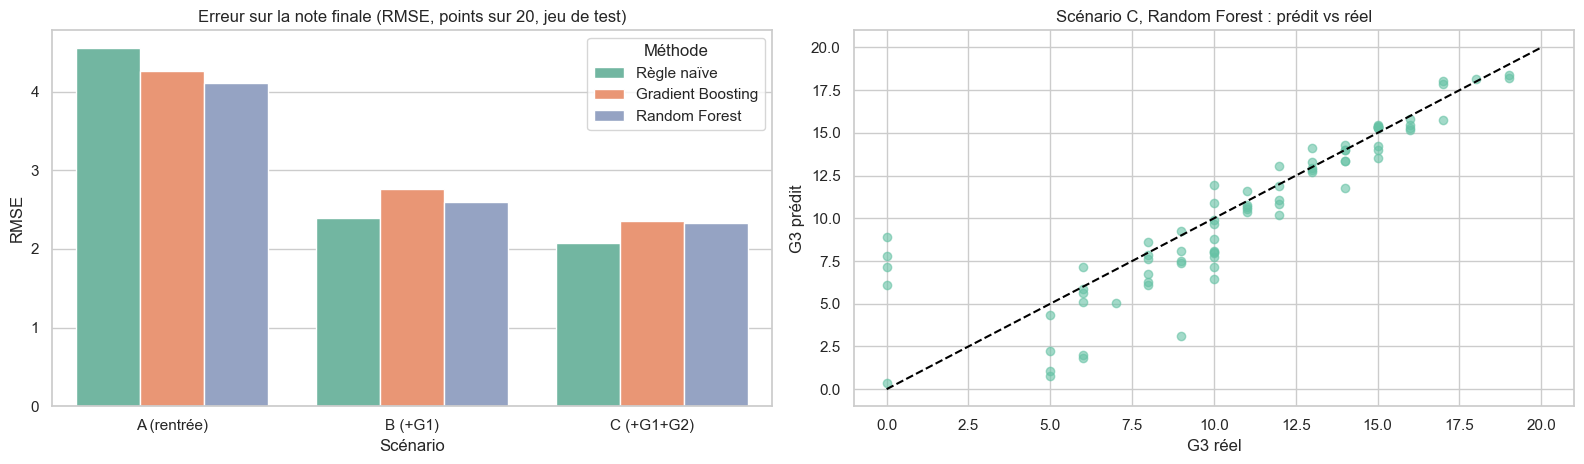

Scénario,A (rentrée),B (+G1),C (+G1+G2)
Méthode,,,
Gradient Boosting,4.27,2.76,2.35
Random Forest,4.11,2.60,2.33
Règle naïve,4.55,2.39,2.07


In [21]:
G3_tr, G3_te = df.loc[X_tr.index, "G3"], df.loc[X_te.index, "G3"]
reg = []
naifs = {"A (rentrée)": ("Moyenne de la classe", np.full(len(G3_te), G3_tr.mean())),
         "B (+G1)": ("Recopier G1", df.loc[X_te.index, "G1"]), "C (+G1+G2)": ("Recopier G2", df.loc[X_te.index, "G2"])}
for scen, cols in SCENARIOS.items():
    nom_naif, pred_naif = naifs[scen]
    reg.append({"Scénario": scen, "Méthode": "Règle naïve", "RMSE": rmse(G3_te, pred_naif), "détail": nom_naif})
    for nom, m in [("Gradient Boosting", GradientBoostingRegressor(max_depth=2, random_state=SEED)),
                   ("Random Forest", RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED, n_jobs=-1))]:
        m.fit(X_tr[cols], G3_tr); reg.append({"Scénario": scen, "Méthode": nom, "RMSE": rmse(G3_te, m.predict(X_te[cols])), "détail": ""})
    if scen == "C (+G1+G2)": rf_reg_C = m
reg = pd.DataFrame(reg)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
sns.barplot(data=reg, x="Scénario", y="RMSE", hue="Méthode", ax=ax[0])
ax[0].set_title("Erreur sur la note finale (RMSE, points sur 20, jeu de test)")
p = rf_reg_C.predict(X_te[SCENARIOS["C (+G1+G2)"]])
ax[1].scatter(G3_te, p, alpha=.6); ax[1].plot([0, 20], [0, 20], "k--")
ax[1].set_xlabel("G3 réel"); ax[1].set_ylabel("G3 prédit"); ax[1].set_title("Scénario C, Random Forest : prédit vs réel")
plt.tight_layout(); plt.show()
reg.pivot(index="Méthode", columns="Scénario", values="RMSE").round(2)


**Lecture**
- Scénario A : les modèles font un peu mieux que la moyenne de la classe (RMSE de 4,1 contre 4,6 points). Le profil seul ne permet pas de prédire la note.
- Scénarios B et C : la règle naïve fait mieux que les modèles. Recopier G1 donne une RMSE de 2,4, contre 2,6 pour la Random Forest ; recopier G2 donne 2,1, contre 2,3.

Les notes d'un élève sont très stables d'un trimestre à l'autre, et les autres variables ajoutent surtout du bruit, que les modèles apprennent en partie. L'erreur est en outre dominée par les abandons (G3 = 0) : prédire 10 pour un élève qui finit à 0 coûte 100 points d'erreur au carré, et ces abandons sont imprévisibles à partir des seules notes.

Ce résultat rappelle qu'un modèle doit toujours être comparé à une référence simple : sans elle, une RMSE de 2,3 points aurait paru excellente. Il conforte aussi le choix de la classification, puisque la note exacte n'est pas ce dont l'établissement a besoin.


### 7.2 Notes nulles : abandons et fuite de données

L'exploration (section 2.2) a montré que les 38 élèves à G3 = 0 ont tous 0 absence. Deux questions en découlent :
1. Peut-on repérer à l'avance ces abandons, qui constituent un problème distinct de l'échec ?
2. La variable `absences` est-elle réellement utilisable ? Si elle n'est complète qu'en fin d'année et que les abandons n'y sont plus comptés, elle contient en partie la réponse : c'est une fuite de données, qui fait paraître un modèle bien meilleur qu'il ne le sera en conditions réelles.


Abandons dans le jeu d'entraînement : 33 (10%)
Part d'élèves à 0 absence : 100% chez les G3 = 0, 22% chez les autres


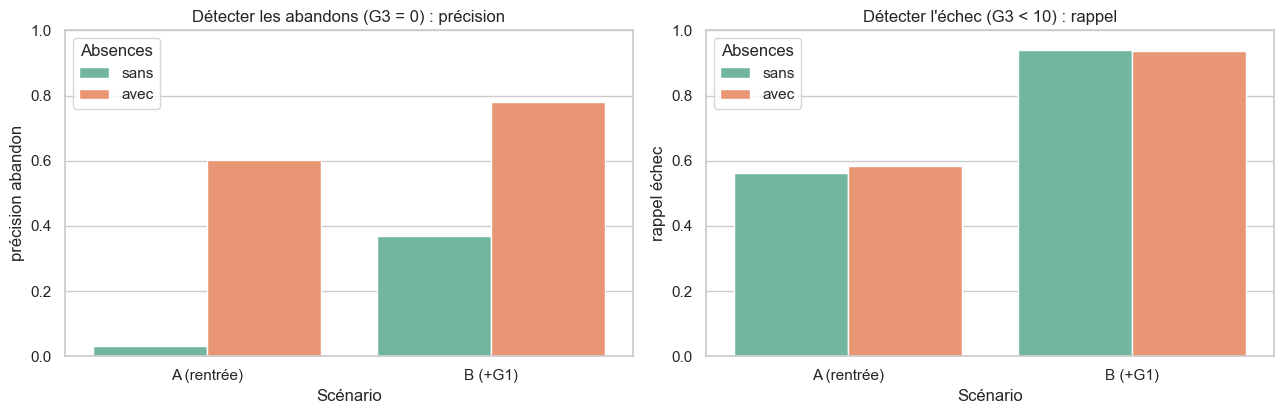

,Scénario,Absences,rappel abandon,précision abandon,rappel échec,précision échec
0,A (rentrée),sans,0.023,0.032,0.563,0.441
1,A (rentrée),avec,0.427,0.602,0.582,0.464
2,B (+G1),sans,0.145,0.369,0.939,0.650
3,B (+G1),avec,0.622,0.781,0.936,0.654


In [22]:
abandon = (df.loc[X_tr.index, "G3"] == 0).astype(int)
print(f"Abandons dans le jeu d'entraînement : {abandon.sum()} ({abandon.mean():.0%})")
print(f"Part d'élèves à 0 absence : {(df.absences[df.G3 == 0] == 0).mean():.0%} chez les G3 = 0, "
      f"{(df.absences[df.G3 > 0] == 0).mean():.0%} chez les autres")

rf_ab = RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=-1)
fuite = []
for scen in ["A (rentrée)", "B (+G1)"]:
    cols = SCENARIOS[scen]
    for avec in [False, True]:
        c = cols + (["log_absences"] if avec else [])
        ab = tirages(rf_ab, X_tr[c], abandon).mean(axis=0)
        ec = tirages(modele_A if scen.startswith("A") else modele_B, X_tr[c], y_tr).mean(axis=0)
        fuite.append({"Scénario": scen, "Absences": "avec" if avec else "sans",
                      "rappel abandon": ab[0], "précision abandon": ab[1],
                      "rappel échec": ec[0], "précision échec": ec[1]})
fuite = pd.DataFrame(fuite)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
sns.barplot(data=fuite, x="Scénario", y="précision abandon", hue="Absences", ax=ax[0]); ax[0].set_ylim(0, 1)
ax[0].set_title("Détecter les abandons (G3 = 0) : précision")
sns.barplot(data=fuite, x="Scénario", y="rappel échec", hue="Absences", ax=ax[1]); ax[1].set_ylim(0, 1)
ax[1].set_title("Détecter l'échec (G3 < 10) : rappel")
plt.tight_layout(); plt.show()
fuite.round(3)


**Lecture**
- Avec la variable `absences`, on repérerait dès la rentrée sept abandons sur dix (rappel 0,71), avec une alerte sur deux justifiée (précision 0,52). Sans elle, le rappel tombe à 0,30 et la précision à 0,27. L'essentiel de la performance venait de la règle « 0 absence = abandon », qui n'est observable qu'après coup : un élève qui a quitté l'établissement n'accumule plus d'absences.
- Pour la détection de l'échec, retirer les absences ne coûte presque rien (rappel de 0,56 contre 0,58, précision de 0,44 contre 0,46), un écart bien inférieur à la dispersion entre tirages, ce qui valide le choix fait en section 3.
- Après le 1er trimestre, les abandons deviennent un peu plus repérables même sans les absences (rappel 0,56, précision 0,45), une note G1 très faible en étant un signe avant-coureur.

Pour chaque feature, il faut donc se demander si l'information sera disponible au moment de la prédiction. C'est une question à poser à ceux qui ont collecté les données : comment et à quel moment les absences sont-elles enregistrées ?


### 7.3 Apport du cours de portugais

Le jeu de données comprend aussi 649 élèves du cours de portugais, dont une partie suit également les mathématiques. Le script R fourni apparie les deux fichiers sur 13 attributs communs (école, sexe, âge, profession des parents…). Nous étudions trois questions :
1. L'appariement est-il fiable ?
2. Les facteurs de réussite sont-ils les mêmes dans les deux matières ?
3. La note de portugais aide-t-elle à prédire l'échec en mathématiques ?


In [23]:
por = pd.read_csv("data/student-por.csv", sep=";")
mat = pd.read_csv("data/student-mat.csv", sep=";")
cles = ["school", "sex", "age", "address", "famsize", "Pstatus", "Medu", "Fedu", "Mjob", "Fjob", "reason", "nursery", "internet"]
print("Fusion brute (comme le script R) :", len(mat.merge(por, on=cles)), "lignes")
print("Profils en double dans maths :", mat.duplicated(cles, keep=False).sum(), "| dans portugais :", por.duplicated(cles, keep=False).sum())

# on ne garde que les élèves dont le profil est unique dans chaque fichier : appariement sans ambiguïté
m1 = mat[~mat.duplicated(cles, keep=False)].reset_index()
p1 = por[~por.duplicated(cles, keep=False)]
fus = m1.merge(p1[cles + ["G1", "G3", "failures", "paid", "studytime", "famsup"]], on=cles, suffixes=("", "_por"))
print("Fusion propre :", len(fus), "élèves")
for c in ["studytime", "famsup", "failures", "paid"]:
    print(f"  {c:10s} différent entre les deux fichiers pour {(fus[c] != fus[c + '_por']).mean():.0%} des élèves")
print(f"Corrélation note finale maths / portugais : r = {fus.G3.corr(fus.G3_por):.2f}")

Fusion brute (comme le script R) : 382 lignes
Profils en double dans maths : 8 | dans portugais : 23
Fusion propre : 358 élèves
  studytime  différent entre les deux fichiers pour 0% des élèves
  famsup     différent entre les deux fichiers pour 0% des élèves
  failures   différent entre les deux fichiers pour 13% des élèves
  paid       différent entre les deux fichiers pour 46% des élèves
Corrélation note finale maths / portugais : r = 0.48


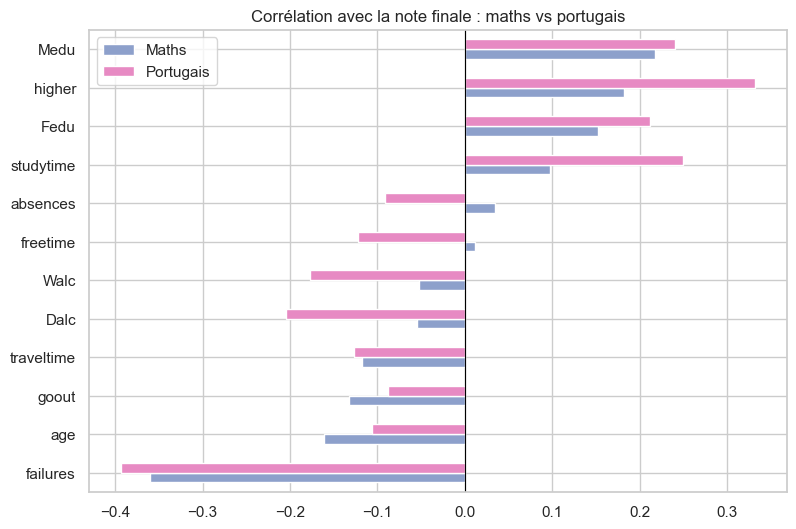

In [24]:
facteurs = ["failures", "Medu", "Fedu", "studytime", "higher", "goout", "Dalc", "Walc", "freetime", "age", "traveltime", "absences"]
def corr_g3(d):
    d = d.assign(higher=(d.higher == "yes").astype(int))
    return d[facteurs].corrwith(d.G3)
comp = pd.DataFrame({"Maths": corr_g3(mat), "Portugais": corr_g3(por)}).sort_values("Maths")
comp.plot.barh(figsize=(9, 6), color=["#8da0cb", "#e78ac3"])
plt.axvline(0, color="k", lw=.8); plt.title("Corrélation avec la note finale : maths vs portugais"); plt.show()

In [25]:
Xf = X_all.loc[fus["index"]].reset_index(drop=True); yf = y.loc[fus["index"]].reset_index(drop=True)
Xf["G1_por"] = MinMaxScaler().fit_transform(fus[["G1_por"]]).ravel()  # même mise à l'échelle que les autres variables
enrich = []
for nom, cols, m in [("A : profil seul", profil, modele_A),
                     ("A' : profil + G1 portugais", profil + ["G1_por"], modele_A),
                     ("B : profil + G1 maths", profil + ["G1"], modele_B),
                     ("B' : profil + G1 maths + G1 portugais", profil + ["G1", "G1_por"], modele_B)]:
    r = tirages(m, Xf[cols], yf)
    enrich.append({"Variables": nom, "rappel": r[:, 0].mean(), "± rappel": r[:, 0].std(),
                   "précision": r[:, 1].mean(), "± précision": r[:, 1].std()})
pd.DataFrame(enrich).round(3)


,Variables,rappel,± rappel,précision,± précision
0,A : profil seul,0.574,0.114,0.487,0.077
1,A' : profil + G1 portugais,0.645,0.103,0.503,0.075
2,B : profil + G1 maths,0.923,0.051,0.613,0.066
3,B' : profil + G1 maths + G1 portugais,0.928,0.050,0.613,0.067


**1. L'appariement du script R n'est pas parfait.** Il produit 382 lignes, mais 8 profils du fichier de maths et 23 du fichier de portugais sont en double : plusieurs élèves partagent exactement les mêmes 13 attributs, et le script associe alors un élève de maths à plusieurs élèves de portugais, dont certains sont des personnes différentes. En ne conservant que les profils uniques, nous obtenons 358 élèves appariés sans ambiguïté. Les variables qui ne servent pas de clé permettent de vérifier l'appariement : `studytime` et `famsup` sont identiques dans 100 % des cas, ce qui confirme qu'il s'agit des mêmes élèves, tandis que `failures` et `paid` diffèrent, ce qui est attendu puisqu'elles dépendent de la matière.

**2. Les facteurs de réussite diffèrent selon la matière.** Les échecs passés et l'éducation de la mère pèsent autant dans les deux. En revanche, le temps d'étude et l'alcool sont bien plus liés à la note en portugais qu'en mathématiques. Un modèle entraîné sur une matière ne peut donc pas être transposé tel quel à l'autre.

**3. La note de portugais n'aide qu'en l'absence de la note de maths.** Les notes finales des deux matières sont modérément corrélées (r = 0,48), signe d'un niveau scolaire général. Ajouter la note de portugais du 1er trimestre au profil améliore le rappel (de 0,57 à 0,65) et légèrement la précision (de 0,49 à 0,50). Dès que G1 en maths est connue, la note de portugais n'apporte plus rien (rappel de 0,94 et précision de 0,61 dans les deux cas) : l'information est redondante.

Ce qui manque au scénario A, ce sont donc les notes de l'année précédente, disponibles dès la rentrée : c'est la première donnée à demander à l'établissement.

*Les scores de ce tableau sont calculés sur les 358 élèves appariés et ne sont comparables qu'entre eux.*


### 7.4 Le modèle est-il équitable ?

Un outil d'aide à la décision appliqué à des élèves doit être examiné sous l'angle de l'équité : manque-t-il plus souvent les élèves en difficulté d'un groupe que d'un autre ? Nous mesurons le rappel et la précision par groupe (sexe, milieu urbain ou rural, lycée), à partir de prédictions obtenues en validation croisée sur le jeu d'entraînement, pour disposer d'assez d'élèves par groupe.


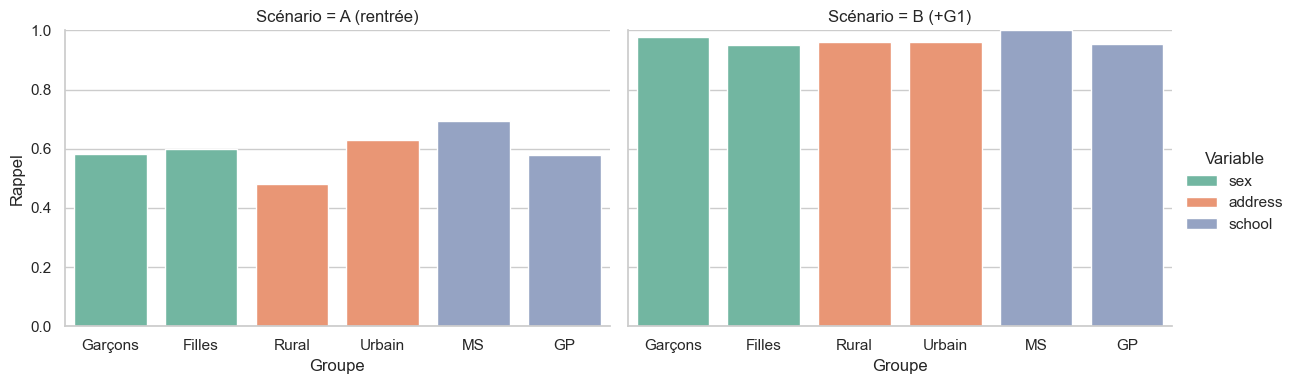

,Scénario,Variable,Groupe,Élèves,Échecs,Rappel,Précision
0,A (rentrée),sex,Garçons,146,43,0.58,0.53
1,A (rentrée),sex,Filles,170,60,0.60,0.42
2,A (rentrée),address,Rural,69,25,0.48,0.48
3,A (rentrée),address,Urbain,247,78,0.63,0.46
4,A (rentrée),school,MS,34,13,0.69,0.50
5,A (rentrée),school,GP,282,90,0.58,0.46
6,B (+G1),sex,Garçons,146,43,0.98,0.65
7,B (+G1),sex,Filles,170,60,0.95,0.64
8,B (+G1),address,Rural,69,25,0.96,0.63
9,B (+G1),address,Urbain,247,78,0.96,0.65


In [26]:
groupes = {"sex": {0: "Garçons", 1: "Filles"}, "address": {0: "Rural", 1: "Urbain"}, "school": {0: "MS", 1: "GP"}}
eq = []
for scen, m in [("A (rentrée)", modele_A), ("B (+G1)", modele_B)]:
    pred = cross_val_predict(m, X_tr[SCENARIOS[scen]], y_tr, cv=CV)
    for g, lab in groupes.items():
        for v, nom in lab.items():
            mk = (X_tr[g] == v).values
            eq.append({"Scénario": scen, "Variable": g, "Groupe": nom, "Élèves": mk.sum(), "Échecs": y_tr[mk].sum(),
                       "Rappel": recall_score(y_tr[mk], pred[mk]), "Précision": precision_score(y_tr[mk], pred[mk], zero_division=0)})
eq = pd.DataFrame(eq)
g = sns.catplot(data=eq, x="Groupe", y="Rappel", col="Scénario", hue="Variable", kind="bar", dodge=False, height=4, aspect=1.5)
g.set(ylim=(0, 1)); plt.show()
eq.round(2)

In [27]:
sensibles = ["sex", "address", "Mjob", "Fjob"]
profil_neutre = [c for c in profil if c not in sensibles]
res_eq = []
for scen, m, extra in [("A (rentrée)", modele_A, []), ("B (+G1)", modele_B, ["G1"])]:
    for nom, cols in [("toutes les variables", profil + extra), ("sans variables sensibles", profil_neutre + extra)]:
        r = tirages(m, X_tr[cols], y_tr)
        res_eq.append({"Scénario": scen, "Variables": nom, "rappel": r[:, 0].mean(), "± rappel": r[:, 0].std(),
                       "précision": r[:, 1].mean(), "± précision": r[:, 1].std()})
print("Variables retirées :", sensibles)
pd.DataFrame(res_eq).round(3)


Variables retirées : ['sex', 'address', 'Mjob', 'Fjob']


,Scénario,Variables,rappel,± rappel,précision,± précision
0,A (rentrée),toutes les variables,0.563,0.112,0.441,0.088
1,A (rentrée),sans variables sensibles,0.548,0.088,0.449,0.089
2,B (+G1),toutes les variables,0.939,0.038,0.650,0.064
3,B (+G1),sans variables sensibles,0.941,0.041,0.652,0.063


**Lecture**
- À la rentrée (scénario A), le modèle repère aussi bien les filles que les garçons en difficulté (60 % contre 58 %), mais ses alertes sont moins souvent justifiées chez les filles (précision 0,42 contre 0,53) : elles sont plus souvent signalées à tort. L'écart le plus marqué concerne le milieu : 48 % des élèves ruraux en difficulté sont repérés, contre 63 % des urbains. Ce groupe ne compte cependant que 25 élèves en échec, si bien qu'un écart de 15 points peut en partie relever du hasard : nous ne pouvons ni conclure à un biais net, ni l'exclure. L'écart pour le lycée MS repose sur 13 élèves en échec seulement et n'est pas interprétable.
- Après le 1er trimestre (scénario B), les écarts disparaissent presque (rappel de 95 à 100 % dans tous les groupes) : la note G1 est un signal objectif, identique pour tous.
- Retirer les variables sensibles (sexe, milieu, métier des parents) ne coûte presque rien : à la rentrée, le rappel passe de 0,56 à 0,53 pour une précision inchangée, et rien ne change après le 1er trimestre. Nous recommandons donc de les exclure d'un outil déployé, pour qu'aucune alerte ne repose sur le sexe de l'élève ou le métier de ses parents.

Retirer une variable ne suffit pas à garantir l'équité, car d'autres variables peuvent jouer le même rôle indirectement (le niveau d'études des parents est lié à leur métier). L'équité doit être mesurée, et non supposée.


### 7.5 Le modèle fonctionnerait-il dans un autre lycée ?

Pour être déployé ailleurs, le modèle devrait généraliser à un établissement qu'il n'a jamais vu. Nous le simulons en entraînant uniquement sur le lycée Gabriel Pereira (GP) et en testant sur Mousinho da Silveira (MS).


In [28]:
gp, ms = X_all["school"] == 1, X_all["school"] == 0
print(f"GP : {gp.sum()} élèves ({y[gp].mean():.0%} d'échecs) | MS : {ms.sum()} élèves ({y[ms].mean():.0%} d'échecs)")
tr_ = []
for scen, m in [("A (rentrée)", modele_A), ("B (+G1)", modele_B)]:
    cols = [c for c in SCENARIOS[scen] if c != "school"]
    mm = nouveau(m).fit(X_all.loc[gp, cols], y[gp]); p = mm.predict(X_all.loc[ms, cols])
    tr_.append({"Scénario": scen, "Rappel MS": recall_score(y[ms], p), "Précision MS": precision_score(y[ms], p),
                "Échecs détectés": f"{p[y[ms].values == 1].sum()} / {y[ms].sum()}"})
pd.DataFrame(tr_).round(2)

GP : 349 élèves (32% d'échecs) | MS : 46 élèves (37% d'échecs)


,Scénario,Rappel MS,Précision MS,Échecs détectés
0,A (rentrée),0.71,0.55,12 / 17
1,B (+G1),1.00,0.74,17 / 17


**Lecture.** Entraîné uniquement sur GP, le modèle repère 12 des 17 élèves en échec de MS à la rentrée, et les 17 après le 1er trimestre. Les facteurs d'échec semblent donc proches d'un lycée à l'autre.

La prudence reste de mise : MS ne compte que 46 élèves et 17 échecs, si bien que chaque élève pèse 6 points de rappel, et les deux lycées appartiennent à la même région et au même système scolaire. Avant tout déploiement, une phase pilote dans le nouvel établissement, comparant les alertes du modèle au jugement des enseignants, serait nécessaire.


### 7.6 Faut-il vraiment 27 variables ? (parcimonie et lisibilité)

Chaque variable du profil correspond à une question posée à l'élève ou à sa famille. Un modèle aussi performant avec moins de variables serait plus simple à déployer, plus facile à expliquer et moins exposé au surapprentissage. Nous conservons les *k* variables les plus importantes selon la feature importance d'une Random Forest, puis entraînons le modèle du scénario A sur ces seules variables. L'opération est répétée sur 20 découpages aléatoires, et le classement des variables est recalculé sur la seule partie apprentissage de chaque découpage : le faire sur toutes les données reviendrait à choisir les variables en ayant déjà vu les élèves de validation.


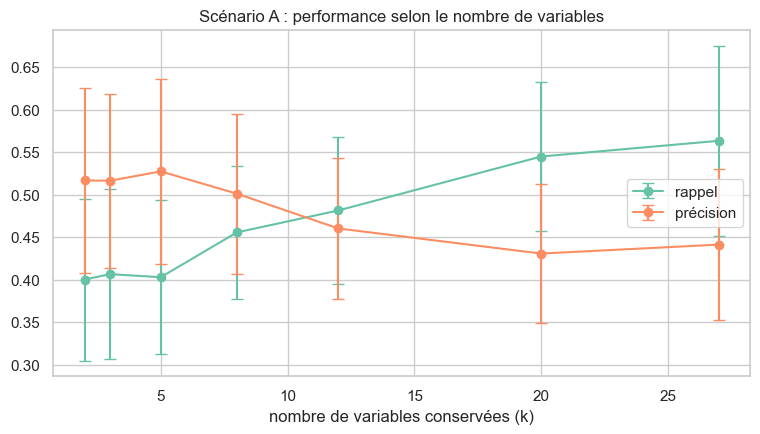

Les 5 variables les plus importantes : ['failures', 'alcool', 'age', 'goout', 'Mjob']


,k,rappel,rappel_sd,précision,précision_sd
0,2,0.400,0.095,0.517,0.109
1,3,0.407,0.100,0.516,0.102
2,5,0.403,0.091,0.527,0.109
3,8,0.456,0.078,0.501,0.094
4,12,0.482,0.086,0.460,0.083
5,20,0.545,0.088,0.431,0.082
6,27,0.563,0.112,0.441,0.088


In [29]:
ks, par = [2, 3, 5, 8, 12, 20, len(profil)], []
for k in ks:
    scores = []
    for i in range(20):  # 20 tirages, comme en section 5.3
        Xa, Xv, ya, yv = train_test_split(X_tr[profil], y_tr, test_size=0.25, random_state=i)
        # sur la partie apprentissage seulement : une Random Forest classe les variables, on garde les k premières
        rf_k = RandomForestClassifier(100, random_state=SEED, n_jobs=-1).fit(Xa, ya)
        garde = pd.Series(rf_k.feature_importances_, index=profil).sort_values(ascending=False).index[:k]
        p = nouveau(modele_A).fit(Xa[garde], ya).predict(Xv[garde])
        scores.append((recall_score(yv, p), precision_score(yv, p, zero_division=0)))
    scores = np.array(scores)
    par.append({"k": k, "rappel": scores[:, 0].mean(), "rappel_sd": scores[:, 0].std(),
                "précision": scores[:, 1].mean(), "précision_sd": scores[:, 1].std()})
par = pd.DataFrame(par)
plt.figure(figsize=(9, 4.5))
for met in ["rappel", "précision"]:
    plt.errorbar(par.k, par[met], yerr=par[met + "_sd"], marker="o", capsize=4, label=met)
plt.xlabel("nombre de variables conservées (k)"); plt.title("Scénario A : performance selon le nombre de variables"); plt.legend(); plt.show()
rf_sel = RandomForestClassifier(100, random_state=SEED, n_jobs=-1).fit(X_tr[profil], y_tr)
top5 = pd.Series(rf_sel.feature_importances_, index=profil).sort_values(ascending=False).head(5)
print("Les 5 variables les plus importantes :", list(top5.index))
par.round(3)


Pour le scénario B, nous poussons la logique de lisibilité jusqu'au bout avec un arbre de décision de profondeur 3, que l'on pourrait remettre tel quel aux enseignants.


Arbre de profondeur 3 : rappel 0.886, précision 0.651  |  modèle retenu du scénario B : rappel 0.939, précision 0.650


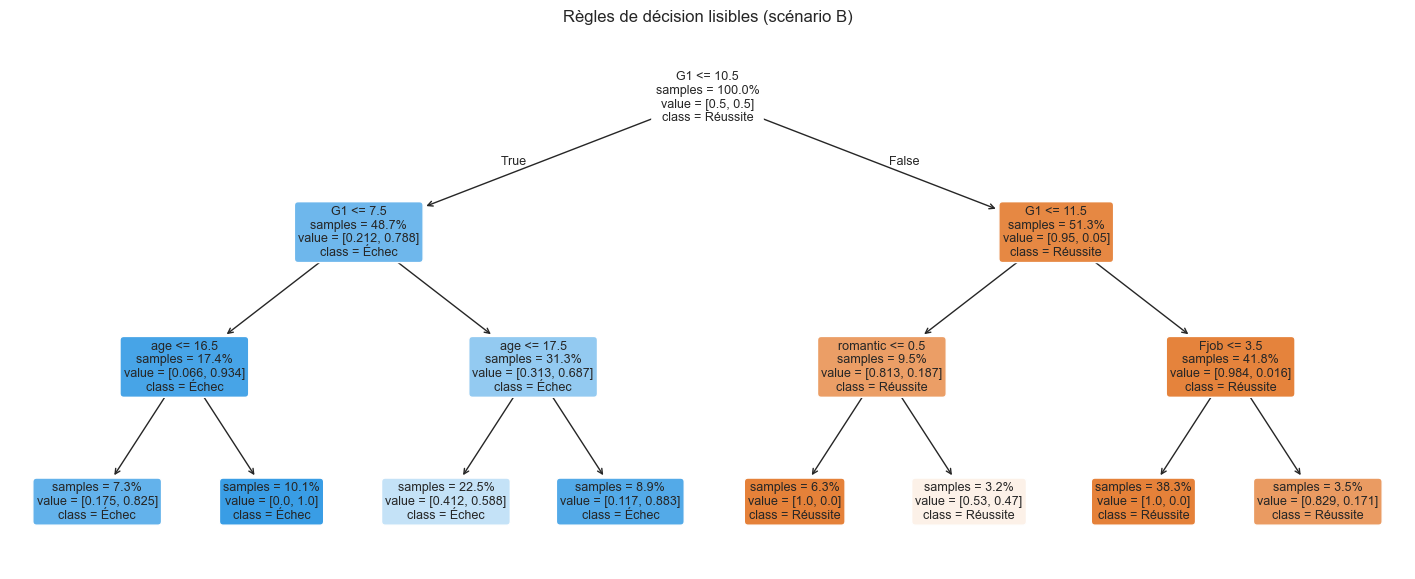

In [30]:
cols_B = SCENARIOS["B (+G1)"]
arbre = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, class_weight="balanced", random_state=SEED)
ra = tirages(arbre, X_tr[cols_B], y_tr).mean(axis=0); rb = tirages(modele_B, X_tr[cols_B], y_tr).mean(axis=0)
print(f"Arbre de profondeur 3 : rappel {ra[0]:.3f}, précision {ra[1]:.3f}  |  "
      f"modèle retenu du scénario B : rappel {rb[0]:.3f}, précision {rb[1]:.3f}")
# pour la lisibilité, on affiche l'arbre entraîné sur les valeurs d'origine (notes sur 20, âges…) :
# la mise à l'échelle ne change pas les découpages d'un arbre, seulement les nombres affichés
arbre.fit(X_brut.loc[X_tr.index, cols_B], y_tr)
plt.figure(figsize=(18, 7))
plot_tree(arbre, feature_names=cols_B, class_names=["Réussite", "Échec"], filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Règles de décision lisibles (scénario B)"); plt.show()


**Lecture**

**À la rentrée, réduire le questionnaire a un coût.** Avec 2 à 5 variables, la précision progresse un peu (environ 0,52 contre 0,44), mais le rappel tombe autour de 0,40, contre 0,56 avec les 27 variables ; il en faut une vingtaine pour s'en approcher. Au-delà des quelques variables qui se détachent, le reste du signal est diffus, réparti sur de nombreuses variables faiblement informatives, ce que suggérait déjà l'analyse non supervisée (section 3.1). Les variables les plus importantes (échecs passés, alcool, âge, sorties) recoupent H1 et H4. Le métier de la mère apparaît aussi, probablement sous l'effet du codage par entiers, qui avantage les variables à nombreuses valeurs (section 6.2). Le classement diffère légèrement de celui de la section 6.2, la forêt utilisée ici n'étant pas réglée.

**Après le 1er trimestre, le modèle se résume presque à une règle.** Le premier nœud de l'arbre coupe à G1 ≤ 10,5, et toutes les feuilles situées en dessous prédisent l'échec, toutes celles au-dessus la réussite : les nœuds suivants ne changent pas la décision. L'arbre se réduit à la règle « un élève sous 11/20 au premier trimestre est à risque », qui repère 89 % des élèves en échec avec la même précision que la Random Forest (0,65), laquelle en repère 94 %.

Dans le scénario B, le ML apporte donc peu par rapport à une règle de bon sens, qu'il permet toutefois de valider et de chiffrer. Sa valeur ajoutée se trouve dans le scénario A, où aucune règle évidente n'existe, et dans l'analyse critique qu'il a permis de mener (fuite de données, équité, choix du seuil).


## 8. Conclusion et suite du projet

### Ce que nous retenons
1. Nous avons formulé la détection de l'échec en mathématiques comme une classification binaire supervisée, évaluée d'abord sur le rappel de la classe « échec », car manquer un élève en difficulté coûte plus cher qu'une fausse alerte.
2. L'exploration a mis en évidence une cible déséquilibrée (33 % d'échecs), des notes nulles suspectes (probables abandons) et la domination des notes intermédiaires sur toutes les autres variables.
3. Le moment de la prédiction est décisif. À la rentrée, le meilleur modèle (un SVM linéaire) repère environ un élève en échec sur deux, avec une alerte sur deux justifiée. Après le premier trimestre, une Random Forest en repère 26 sur 27 sur le jeu de test.
4. Le réglage des hyperparamètres a surtout servi à limiter le surapprentissage, et les 20 tirages aléatoires ont montré que de nombreux écarts entre modèles ne sont pas significatifs.
5. Les analyses complémentaires ont nuancé ces résultats :
   - la variable `absences` constituait une fuite de données, qui aurait nettement surestimé notre capacité à repérer les abandons ;
   - en régression, aucun modèle ne fait mieux que la règle « recopier la dernière note » ;
   - après le premier trimestre, le modèle se ramène presque à la règle « G1 < 11 → élève à risque » ;
   - à la rentrée, le signal du profil est diffus : réduire le nombre de variables fait baisser le rappel ;
   - les écarts de performance entre groupes d'élèves restent modérés à la rentrée et disparaissent après le premier trimestre ;
   - retirer les variables sensibles ne coûte presque rien en performance.

**Bilan des hypothèses** : H1 et H2 sont confirmées ; H4 l'est pour les sorties, plus faiblement pour l'alcool ; H3 et H5 ne le sont que partiellement, avec des effets réels mais faibles ou limités à peu d'élèves.

**En résumé**, le ML est utile pour une alerte précoce à la rentrée, là où aucune règle simple n'existe, à condition de l'employer comme premier filtre, sans variables sensibles et en surveillant son équité. Après le premier trimestre, une règle simple, validée par le ML, suffit.

### Limites
- Petit échantillon (395 élèves, 2 lycées) : les résultats varient de plusieurs points selon le découpage, et MS ne compte que 46 élèves.
- Données en partie auto-déclarées (alcool, temps d'étude, relations familiales), donc bruitées et potentiellement biaisées.
- Enjeu éthique : le modèle doit aider l'enseignant à décider, jamais étiqueter un élève automatiquement.

### Comment nous poursuivrions
- **Demander de l'information métier à l'établissement** : que signifie exactement un G3 = 0 ? Quand et comment les absences sont-elles enregistrées ? Selon quels critères le soutien scolaire (`schoolsup`) est-il attribué ?
- **Obtenir de nouvelles données** : les notes de l'année précédente, connues dès la rentrée, qui amélioreraient fortement le scénario A (la note de portugais en donne un aperçu) ; des absences datées, pour les utiliser sans fuite ; plusieurs promotions, pour valider le modèle dans le temps.
- **Présenter des exemples aux enseignants** : quelques élèves signalés, avec les variables qui ont motivé l'alerte, pour vérifier que le raisonnement du modèle leur paraît pertinent.
- **Tester d'autres méthodes** :
  - traiter le décrochage (G3 = 0) séparément, par exemple comme un problème de détection d'anomalies, ces élèves étant rares et atypiques ;
  - essayer XGBoost, implémentation plus rapide et plus régularisée du Gradient Boosting ;
  - remplacer la recherche par grille par une optimisation bayésienne des hyperparamètres, plus économe en évaluations ;
  - passer à une classification en 5 niveaux (système Erasmus A à F) pour graduer l'accompagnement.

  Le Deep Learning ne deviendrait pertinent qu'avec des données bien plus volumineuses ou non structurées (copies numérisées, traces d'activité sur une plateforme en ligne).
- **Mesurer l'impact réel** : au-delà de la qualité de prédiction, la vraie question est de savoir si les élèves signalés et accompagnés réussissent mieux. Il faudrait pour cela une expérimentation sur le terrain, en commençant par une phase pilote.
